# GameTheory-06-EvolutionTrust-Python

**Navigation** : [<< 5c-KKT-Dualite](GameTheory-05c-KKT-Dualite-Lagrangienne-Python.ipynb) | [Index](README.md) | [06i — Ensembles limites](GameTheory-06i-Ensembles-Limites-Poincare-Bendixson-Python.ipynb) | [7-ExtensiveForm >>](GameTheory-07-ExtensiveForm-Python.ipynb)

## Evolution de la Confiance et Dilemme du Prisonnier Itere

Ce notebook explore le **Dilemme du Prisonnier Itere** (IPD) et l'evolution de la cooperation, inspire par le travail d'Axelrod et la simulation interactive ["The Evolution of Trust"](https://ncase.me/trust/) de Nicky Case.

### Objectifs d'apprentissage

1. Comprendre le Dilemme du Prisonnier Itere
2. Implementer les stratégies classiques (Tit-for-Tat, Hawks, Doves...)
3. Reproduire le tournoi d'Axelrod (1984)
4. Simuler l'evolution des populations (replicator dynamics)
5. Identifier les conditions pour l'emergence de la cooperation

### Prerequis

- Notebooks 1-5 : Fondations, equilibres de Nash, jeux a somme nulle
- Notion de stratégie dominante et de dilemme du prisonnier
- Bases de dynamique des systèmes (optionnel)

### Duree estimee : 65 minutes

### References
- Axelrod, R. (1984). *The Evolution of Cooperation*
- Nicky Case - [The Evolution of Trust](https://ncase.me/trust/)

## Références

**Osborne & Rubinstein (1994)**, §3.4 « Evolutionary Equilibrium » : la dynamique de selection dont le tournoi d'Axelrod et la simulation de confiance sont une instance. Condense : **Leyton-Brown & Shoham (2008)**, §3.8 « Evolutionarily Stable Strategies ». Gisement cluster : `G:\Mon Drive\MyIA\IA\Bibliographie IA\GameTheory\`.


In [25]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from typing import List, Tuple, Dict, Callable
from dataclasses import dataclass, field
from abc import ABC, abstractmethod
import random
import copy
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')
print("Imports OK : numpy, matplotlib, random")


Imports OK : numpy, matplotlib, random


## 1. Le Dilemme du Prisonnier Itere (IPD)

### Du jeu unique au jeu repete

Dans le Dilemme du Prisonnier **unique**, la stratégie dominante est de trahir.

Mais quand le jeu est **repete** (potentiellement indefiniment), la cooperation peut emerger !

### Matrice des gains (convention Axelrod)

|  | Cooperer | Trahir |
|--|----------|--------|
| **Cooperer** | (R, R) = (3, 3) | (S, T) = (0, 5) |
| **Trahir** | (T, S) = (5, 0) | (P, P) = (1, 1) |

- **T** (Temptation) = 5 : Trahir quand l'autre coopere
- **R** (Reward) = 3 : Cooperation mutuelle
- **P** (Punishment) = 1 : Trahison mutuelle
- **S** (Sucker) = 0 : Cooperer quand l'autre trahit

Condition du dilemme : T > R > P > S et 2R > T + S

In [26]:
# Actions
COOPERATE = 'C'
DEFECT = 'D'

# Matrice des gains (convention Axelrod)
T, R, P, S = 5, 3, 1, 0  # Temptation, Reward, Punishment, Sucker

def payoff(action1: str, action2: str) -> Tuple[int, int]:
    """
    Retourne les gains (joueur1, joueur2) pour une paire d'actions.
    """
    if action1 == COOPERATE and action2 == COOPERATE:
        return (R, R)
    elif action1 == COOPERATE and action2 == DEFECT:
        return (S, T)
    elif action1 == DEFECT and action2 == COOPERATE:
        return (T, S)
    else:  # DEFECT, DEFECT
        return (P, P)

# Verification de la condition du dilemme
print(f"Gains: T={T}, R={R}, P={P}, S={S}")
print(f"Condition T > R > P > S: {T > R > P > S}")
print(f"Condition 2R > T + S: {2*R > T + S} ({2*R} > {T+S})")

Gains: T=5, R=3, P=1, S=0
Condition T > R > P > S: True
Condition 2R > T + S: True (6 > 5)


**Lecture chiffree — les deux conditions passees au banc.** La sortie ne redefinit pas la matrice, elle la verifie : `Condition T > R > P > S: True` puis `Condition 2R > T + S: True (6 > 5)`. Les deux nombres de la parenthese se decodent en une ligne : 2R = 6 et T + S = 5, l'ecart vaut 1. Pourquoi ce second test alors que le premier suffit a ordonner les gains ? Parce qu'il verrouille la porte de l'alternance : deux joueurs qui se repartiraient trahison et duperie tour a tour engrangeraient (T + S) / 2 = 2,5 points par coup en moyenne — moins que les R = 3 de la cooperation mutuelle. Avec 2R > T + S, cooperer a chaque coup domine toute strategie d'alternance : le dilemme reste entier, sans issue par la rotation des roles.


## 2. Stratégies classiques

Implementons les stratégies les plus connues du tournoi d'Axelrod.

In [27]:
class Strategy(ABC):
    """
    Classe de base pour les strategies IPD.
    """
    
    def __init__(self, name: str = "Strategy"):
        self.name = name
        self.reset()
    
    def reset(self):
        """Reinitialise l'etat interne."""
        self.my_history: List[str] = []
        self.opponent_history: List[str] = []
    def clone(self) -> "Strategy":
        """Copie fraiche conservant la configuration (parametres d init).
        Les tournois (run_tournament, compute_payoff_matrix) appellent
        clone() au lieu de re-instancier la classe avec ses parametres
        par defaut (#20327, voir egalement #20304 / PR #20328 pour le
        module partage). Le reset() final est indispensable : les
        sous-classes qui surchargent reset() (ex. Grudger.betrayed)
        sont reinitialisees correctement, et l historique de partie
        est vide pour le match suivant.
        """
        cloned = copy.copy(self)
        cloned.reset()
        return cloned
    
    @abstractmethod
    def choose(self) -> str:
        """Choisit une action basee sur l'historique."""
        pass
    
    def update(self, my_action: str, opponent_action: str):
        """Met a jour l'historique apres un tour."""
        self.my_history.append(my_action)
        self.opponent_history.append(opponent_action)
    
    def __repr__(self):
        return self.name


class AlwaysCooperate(Strategy):
    """Coopere toujours (Dove / Colombe)."""
    
    def __init__(self):
        super().__init__("AlwaysCooperate")
    
    def choose(self) -> str:
        return COOPERATE


class AlwaysDefect(Strategy):
    """Trahit toujours (Hawk / Faucon)."""
    
    def __init__(self):
        super().__init__("AlwaysDefect")
    
    def choose(self) -> str:
        return DEFECT


class TitForTat(Strategy):
    """
    Tit-for-Tat (Copycat / Donnant-donnant).
    
    - Coopere au premier tour
    - Ensuite, copie le dernier coup de l'adversaire
    
    Gagnant du tournoi d'Axelrod (1980).
    """
    
    def __init__(self):
        super().__init__("TitForTat")
    
    def choose(self) -> str:
        if not self.opponent_history:
            return COOPERATE
        return self.opponent_history[-1]


class TitForTwoTats(Strategy):
    """
    Tit-for-Two-Tats (Copykitten / Rancunier indulgent).
    
    - Coopere jusqu'a ce que l'adversaire trahisse DEUX fois de suite
    - Plus indulgent que TFT face aux erreurs
    """
    
    def __init__(self):
        super().__init__("TitForTwoTats")
    
    def choose(self) -> str:
        if len(self.opponent_history) < 2:
            return COOPERATE
        # Trahit seulement si l'adversaire a trahi les 2 derniers tours
        if self.opponent_history[-1] == DEFECT and self.opponent_history[-2] == DEFECT:
            return DEFECT
        return COOPERATE


class Grudger(Strategy):
    """
    Grudger (Rancunier / Grim Trigger).
    
    - Coopere jusqu'a la premiere trahison
    - Apres une trahison, ne pardonne JAMAIS
    """
    
    def __init__(self):
        super().__init__("Grudger")
        self.betrayed = False
    
    def reset(self):
        super().reset()
        self.betrayed = False
    
    def choose(self) -> str:
        if self.betrayed:
            return DEFECT
        return COOPERATE
    
    def update(self, my_action: str, opponent_action: str):
        super().update(my_action, opponent_action)
        if opponent_action == DEFECT:
            self.betrayed = True


class Random(Strategy):
    """Joue aleatoirement avec probabilite p de cooperer.

    La graine est portee par l'instance (`random.Random(seed)`), comme le
    jumeau C# `RandomStrat(int seed = 42)`. `clone()` rend un generateur neuf
    a graine identique : chaque match repart du meme etat aleatoire, comme la
    fabrique C# `new RandomStrat(42)` (#21763).
    """

    def __init__(self, p: float = 0.5, seed: int = 42):
        super().__init__(f"Random(p={p})")
        self.p = p
        self.seed = seed
        self.rng = random.Random(seed)

    def clone(self) -> "Random":
        cloned = super().clone()
        cloned.rng = random.Random(self.seed)
        return cloned

    def choose(self) -> str:
        return COOPERATE if self.rng.random() < self.p else DEFECT


class Pavlov(Strategy):
    """
    Pavlov (Win-Stay, Lose-Shift).
    
    - Repete l'action si elle a rapporte un bon gain (R ou T)
    - Change sinon
    """
    
    def __init__(self):
        super().__init__("Pavlov")
    
    def choose(self) -> str:
        if not self.my_history:
            return COOPERATE
        
        last_mine = self.my_history[-1]
        last_opp = self.opponent_history[-1]
        
        # Bon resultat (R ou T) -> repeter
        if (last_mine == COOPERATE and last_opp == COOPERATE) or \
           (last_mine == DEFECT and last_opp == COOPERATE):
            return last_mine
        # Mauvais resultat -> changer
        return DEFECT if last_mine == COOPERATE else COOPERATE


class SuspiciousTitForTat(Strategy):
    """TFT mais commence par trahir."""
    
    def __init__(self):
        super().__init__("SuspiciousTFT")
    
    def choose(self) -> str:
        if not self.opponent_history:
            return DEFECT  # Mefiant au debut
        return self.opponent_history[-1]


# Liste des strategies
STRATEGIES = [
    AlwaysCooperate,
    AlwaysDefect,
    TitForTat,
    TitForTwoTats,
    Grudger,
    Random,
    Pavlov,
    SuspiciousTitForTat,
]

print("Strategies implementees:")
for StratCls in STRATEGIES:
    strat = StratCls()
    print(f"  - {strat.name}")

Strategies implementees:
  - AlwaysCooperate
  - AlwaysDefect
  - TitForTat
  - TitForTwoTats
  - Grudger
  - Random(p=0.5)
  - Pavlov
  - SuspiciousTFT


**Lecture chiffree — le plateau de depart se lit en quatre familles.** Le `print` final enumere les huit strategies qui disputeront tous les matchs du notebook : les gentils d'entree (`AlwaysCooperate`, `TitForTat`, `TitForTwoTats`, `Grudger` — aucun ne trahit en premier), le defecteur pur (`AlwaysDefect`), le bruit (`Random(p=0.5)`, une trahison sur deux en esperance), et deux profils atypiques : `Pavlov`, qui ne change de comportement qu'apres un coup mal paye, et `SuspiciousTFT`, le seul du plateau a ouvrir par la trahison. Cette grammaire — nice, retaliating, forgiving — est exactement celle que le tableau final de la section 8 resumera ; le tournoi la mettra a l'epreuve en croisant chaque famille avec les sept autres.


## 3. Simulation d'un match

Simulons des rencontres entre stratégies.

In [28]:
def play_match(strategy1: Strategy, strategy2: Strategy, 
               rounds: int = 200, noise: float = 0.0,
               seed: int = 0) -> Tuple[int, int]:
    """
    Simule un match entre deux strategies.
    
    Args:
        strategy1, strategy2: Les deux strategies
        rounds: Nombre de tours
        noise: Probabilite d'erreur (action inversee)
        seed: Graine du generateur de bruit ; il n'est cree que si
            `noise > 0`, comme dans le jumeau C# (`new Random(seed)` n'est
            instancie que si le bruit est actif) (#21763)
    
    Returns:
        (score1, score2)
    """
    strategy1.reset()
    strategy2.reset()
    
    score1, score2 = 0, 0
    rng = random.Random(seed) if noise > 0 else None
    
    for _ in range(rounds):
        # Choisir les actions
        action1 = strategy1.choose()
        action2 = strategy2.choose()
        
        # Appliquer le bruit (erreurs de transmission)
        if rng is not None:
            if rng.random() < noise:
                action1 = DEFECT if action1 == COOPERATE else COOPERATE
            if rng.random() < noise:
                action2 = DEFECT if action2 == COOPERATE else COOPERATE
        
        # Calculer les gains
        p1, p2 = payoff(action1, action2)
        score1 += p1
        score2 += p2
        
        # Mettre a jour les historiques
        strategy1.update(action1, action2)
        strategy2.update(action2, action1)
    
    return score1, score2

# Test: TitForTat vs AlwaysDefect
tft = TitForTat()
defector = AlwaysDefect()

s1, s2 = play_match(tft, defector, rounds=100)
print(f"TitForTat vs AlwaysDefect (100 tours):")
print(f"  TFT: {s1}, Defector: {s2}")

# TitForTat vs TitForTat
tft1 = TitForTat()
tft2 = TitForTat()
s1, s2 = play_match(tft1, tft2, rounds=100)
print(f"\nTitForTat vs TitForTat (100 tours):")
print(f"  TFT1: {s1}, TFT2: {s2}")

TitForTat vs AlwaysDefect (100 tours):
  TFT: 99, Defector: 104

TitForTat vs TitForTat (100 tours):
  TFT1: 300, TFT2: 300


### Interpretation : résultats des matchs

Les deux matchs tests illustrent la dynamique fondamentale du dilemme du prisonnier itere :

**Match 1 : TFT vs AlwaysDefect (100 tours)**

| Tour | TFT | Defector | Gains TFT | Gains Defector |
|------|-----|----------|-----------|----------------|
| 1 | C | D | S=0 | T=5 |
| 2-100 | D | D | P=1 | P=1 |
| **Total** | - | - | **99** | **104** |

TitForTat "perd" le match direct car il subit le coup S=0 au premier tour avant de riposter.

**Match 2 : TFT vs TFT (100 tours)**

| Chaque tour | TFT1 | TFT2 | Gains |
|-------------|------|------|-------|
| Tous | C | C | R=3 chacun |
| **Total** | - | - | **300** chacun |

Deux TFT cooperent parfaitement et obtiennent le gain maximal possible.

> **Point cle** : Un defecteur bat un cooperateur en match direct, mais deux cooperateurs obtiennent ensemble bien plus qu'un defecteur seul.

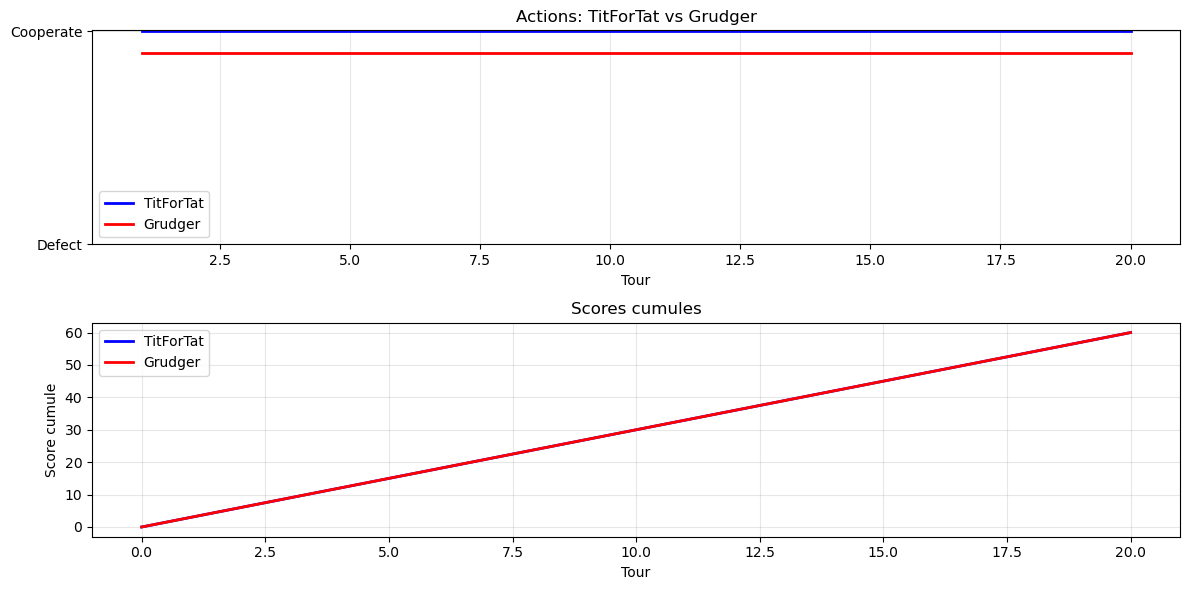

Score final: TitForTat=60, Grudger=60


In [29]:
def visualize_match(strategy1: Strategy, strategy2: Strategy, rounds: int = 30):
    """
    Visualise un match tour par tour.
    """
    strategy1.reset()
    strategy2.reset()
    
    history1, history2 = [], []
    scores1, scores2 = [0], [0]
    
    for _ in range(rounds):
        a1 = strategy1.choose()
        a2 = strategy2.choose()
        
        history1.append(1 if a1 == COOPERATE else 0)
        history2.append(1 if a2 == COOPERATE else 0)
        
        p1, p2 = payoff(a1, a2)
        scores1.append(scores1[-1] + p1)
        scores2.append(scores2[-1] + p2)
        
        strategy1.update(a1, a2)
        strategy2.update(a2, a1)
    
    # Visualisation
    fig, axes = plt.subplots(2, 1, figsize=(12, 6))
    
    # Actions
    ax = axes[0]
    x = range(1, rounds + 1)
    ax.step(x, history1, 'b-', where='mid', label=strategy1.name, linewidth=2)
    ax.step(x, [h - 0.1 for h in history2], 'r-', where='mid', label=strategy2.name, linewidth=2)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Defect', 'Cooperate'])
    ax.set_xlabel('Tour')
    ax.set_title(f'Actions: {strategy1.name} vs {strategy2.name}')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Scores cumules
    ax = axes[1]
    ax.plot(range(rounds + 1), scores1, 'b-', label=f'{strategy1.name}', linewidth=2)
    ax.plot(range(rounds + 1), scores2, 'r-', label=f'{strategy2.name}', linewidth=2)
    ax.set_xlabel('Tour')
    ax.set_ylabel('Score cumule')
    ax.set_title('Scores cumules')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print(f"Score final: {strategy1.name}={scores1[-1]}, {strategy2.name}={scores2[-1]}")

# Visualiser TFT vs Grudger
visualize_match(TitForTat(), Grudger(), rounds=20)

### Interpretation : dynamique des matchs

La visualisation TFT vs Grudger illustre deux stratégies "nice" qui cooperent parfaitement :

**Graphique des actions** :
- Les deux lignes restent a "Cooperate" pendant tout le match
- Aucune trahison n'est declenchee car aucun des deux ne commence

**Graphique des scores cumules** :
- Les scores evoluent de maniere identique (pente = R = 3 par tour)
- Score final egal : 60 points chacun sur 20 tours

> **Principe** : Deux stratégies "nice" (qui ne trahissent jamais en premier) cooperent toujours et obtiennent le gain maximal mutuel.

La cellule suivante montre un cas plus interessant : TFT vs SuspiciousTFT.

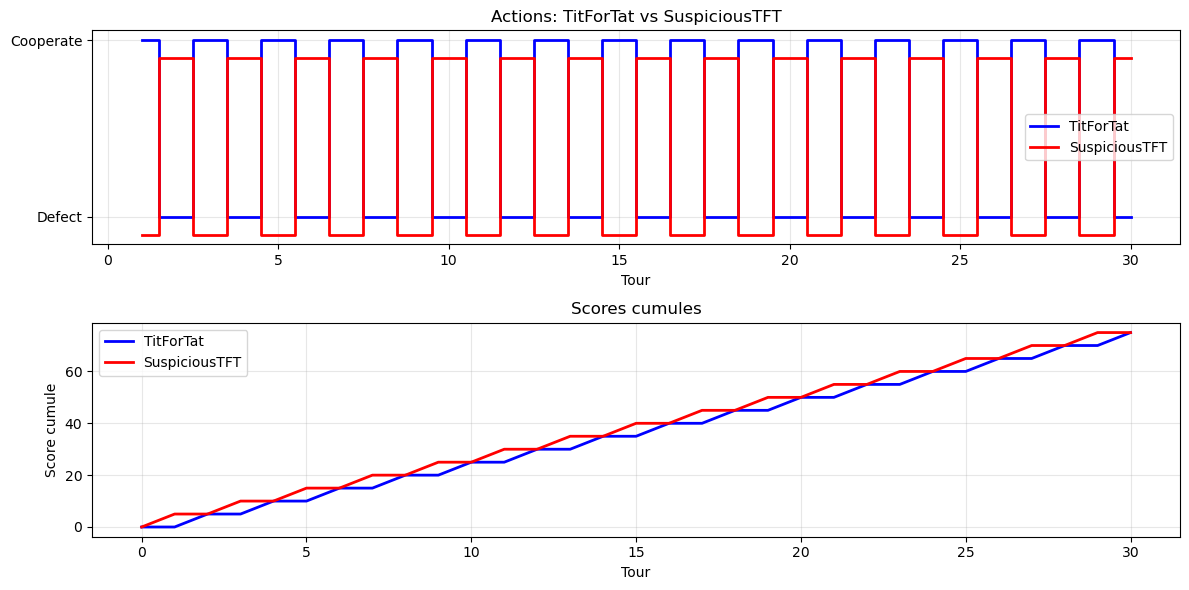

Score final: TitForTat=75, SuspiciousTFT=75


In [30]:
# Visualiser TFT vs SuspiciousTFT
visualize_match(TitForTat(), SuspiciousTitForTat(), rounds=30)

**75 partout : l'alternance verrouillée.** Le score final `TitForTat=75, SuspiciousTFT=75` sur 30 coups se decode exactement. Un seul coup les separe a l'ouverture : TitForTat coopere, SuspiciousTFT trahit — gains 0 contre 5. Ensuite les deux reflexes se renvoient la defection et la cooperation en quinconce : chacun joue D quand l'autre vient de jouer C, et C quand l'autre vient de jouer D. Trente coups d'alternance stricte donnent a chaque joueur quinze trahisons recompensees et quinze duperies : 15 x 5 + 15 x 0 = 75. La figure au-dessus raconte la meme histoire en barres croisees. Ce score egale et mediant porte la lecon du regime : une seule defaite d'ouverture entre deux strategies miroirs verrouille l'alternance pour toujours — ni la cooperation mutuelle (3 x 30 = 90) ni la defection generale (1 x 30 = 30) ne seront atteintes, et le total commun 75 + 75 = 150 reste sous les 180 que la cooperation mutuelle aurait payes.


## 4. Tournoi d'Axelrod

Reproduisons le celebre tournoi d'Axelrod (1980) ou chaque stratégie affronte toutes les autres.

**Protocole de lecture — ce que mesure la colonne Score moyen.** Chaque strategie joue 200 coups contre chacune des sept autres : le score affiche est le gain moyen par rencontre -- un total de points, pas un bilan de victoires et de defaites. Une strategie peut perdre plusieurs duels et finir premiere : le classement recompense qui collecte le plus sur l'ensemble des rencontres, adversaires gentils compris.

In [31]:
def run_tournament(strategies: List[Strategy], 
                   rounds: int = 200, 
                   noise: float = 0.0,
                   repetitions: int = 1) -> Dict[str, float]:
    """
    Execute un tournoi round-robin.
    
    Args:
        strategies: Liste des strategies participantes
        rounds: Nombre de tours par match
        noise: Probabilite d'erreur
        repetitions: Nombre de repetitions pour moyenner (utile avec bruit)
    
    Returns:
        Dictionnaire {nom_strategie: score_moyen_par_match}
    """
    n = len(strategies)
    scores = defaultdict(float)
    match_count = defaultdict(int)
    rng_seed = 1  # graine de bruit incrementee a chaque match, comme en C# (#21763)
    
    for _ in range(repetitions):
        for i in range(n):
            for j in range(n):
                # Creer des instances fraiches
                s1 = strategies[i].clone()
                s2 = strategies[j].clone()
                
                score1, score2 = play_match(s1, s2, rounds, noise, rng_seed)
                rng_seed += 1
                
                scores[strategies[i].name] += score1
                scores[strategies[j].name] += score2
                match_count[strategies[i].name] += 1
                match_count[strategies[j].name] += 1
    
    # Calculer la moyenne par match
    avg_scores = {name: scores[name] / match_count[name] for name in scores}
    
    return avg_scores

def display_tournament_results(results: Dict[str, float], title: str = "Tournoi"):
    """Affiche les resultats du tournoi."""
    sorted_results = sorted(results.items(), key=lambda x: -x[1])
    
    print(f"\n{title}")
    print("=" * 50)
    print(f"{'Rang':<5} {'Strategie':<20} {'Score moyen':<12}")
    print("-" * 50)
    
    for rank, (name, score) in enumerate(sorted_results, 1):
        print(f"{rank:<5} {name:<20} {score:<12.2f}")

# Creer les instances
tournament_strategies = [StratCls() for StratCls in STRATEGIES]

# Tournoi sans bruit
results = run_tournament(tournament_strategies, rounds=200, noise=0.0)
display_tournament_results(results, "Tournoi d'Axelrod (sans bruit)")


Tournoi d'Axelrod (sans bruit)
Rang  Strategie            Score moyen 
--------------------------------------------------
1     TitForTwoTats        522.62      
2     TitForTat            518.75      
3     Grudger              501.62      
4     Pavlov               493.00      
5     AlwaysCooperate      488.25      
6     Random(p=0.5)        425.62      
7     AlwaysDefect         403.50      
8     SuspiciousTFT        395.00      


### Lecture chiffree -- les trois paquets du classement

Le tournoi range les huit strategies en trois paquets, avec un **vrai fossé entre cooperateurs et defection pure**, pas entre cooperateurs retaliers et cooperateurs naifs :

- **Quatre retalieurs en tete** (TitForTwoTats 522.62, TitForTat 518.75, Grudger 501.62, Pavlov 493.00), serres en haut du classement. La cooperation retaliciatrice domine la cooperation naieve : les strategies qui ripostent maintiennent la cooperation et captent les gains des duels mutuels.
- **AlwaysCooperate juste derriere** (488.25, a moins de cinq points de Pavlov). Le saut est modeste : la cooperation naieve perd quelques duels contre les retalieurs mais profite de leur retour cooperatif.
- **Le vrai fosse, plus de 60 points, separe tous les cooperateurs de Random** (488.25 contre 425.62). Subir la duperie dans un champ a majorite gentille vaut mieux que distribuer la trahison aleatoirement.
- **En bas du tableau, AlwaysDefect (403.50) devance SuspiciousTFT (395.00) de quelques points**. SuspiciousTFT perd chaque rencontre contre les cinq gentils du champ a cause de sa trahison d'ouverture : il declenche la riposte et reste bloque en defaite mutuelle.

**Le paradoxe du match direct** : AlwaysDefect bat TitForTat en duel (104 contre 99 sur 100 tours, match 1 plus haut), et finit pourtant avant-dernier du tournoi (403.50 contre 518.75). Les deux mesures ne se contredisent pas, elles ne comptent pas la meme chose : le duel isole ne recompense que l'exploitation d'un partenaire unique, tandis que le tournoi additionne les rencontres contre les huit strategies, dont les cinq gentilles qui ferment la cooperation des la premiere trahison. Gagner un duel ne fait donc pas une bonne strategie : cela fait une strategie dont le gain depend d'avoir un exploite a portee.

**Les valeurs sont reproductibles** : le tirage de Random(p=0.5) n'est plus libre. La classe porte un `random.Random(42)` par instance, et chaque clone repart de la meme graine -- comme le jumeau C# `RandomStrat(42)` et sa fabrique `new RandomStrat(42)`. Le bruit est tire d'un generateur cree par match, dont la graine est incrementee a chaque rencontre (`rng_seed`), comme dans le jumeau C#. Un second passage kernel rend donc **le meme tableau** : la graine n'est plus ce qui faisait bouger le classement d'une execution a l'autre.

Ces résultats reproduisent les découvertes historiques d'Axelrod (1980) : les stratégies gagnantes sont **nice** (elles ne défectionnent jamais les premières), **retaliating** (elles ripostent à la défection) et, pour les deux premières du classement, **forgiving** (elles ne gardent pas rancune — TitForTwoTats pardonne un défaut isolé, Grudger jamais). Les scores sont reproductibles : la graine est fixée (#21763), un second passage rend le même classement.

In [32]:
# Tournoi avec bruit (5% d'erreurs)
results_noisy = run_tournament(tournament_strategies, rounds=200, noise=0.05, repetitions=10)
display_tournament_results(results_noisy, "Tournoi avec bruit (5% d'erreurs)")


Tournoi avec bruit (5% d'erreurs)
Rang  Strategie            Score moyen 
--------------------------------------------------
1     TitForTwoTats        443.69      
2     Pavlov               443.68      
3     TitForTat            434.84      
4     Grudger              431.13      
5     SuspiciousTFT        429.99      
6     AlwaysDefect         427.87      
7     Random(p=0.5)        425.29      
8     AlwaysCooperate      383.80      


### Interpretation : effet du bruit sur le classement

L'introduction de 5% de bruit (erreurs de transmission) deplace le bas du classement :

| Sans bruit | Avec bruit (5%) | Evolution |
|------------|-----------------|-----------|
| 1. TitForTwoTats | 1. TitForTwoTats | Stable (leader #1) |
| 2. TitForTat | 2. Pavlov | Forte hausse (#4 -> #2) |
| 3. Grudger | 3. TitForTat | Recule (#2 -> #3) |
| 4. Pavlov | 4. Grudger | Recule (#3 -> #4) |
| 5. AlwaysCooperate | 5. SuspiciousTFT | Forte hausse (#8 -> #5) |
| 6. Random(p=0.5) | 6. AlwaysDefect | Hausse (#7 -> #6) |
| 7. AlwaysDefect | 7. Random(p=0.5) | Recule (#6 -> #7) |
| 8. SuspiciousTFT | 8. AlwaysCooperate | Chute (#5 -> #8) |

**Mécanismes observes** :

1. **TitForTwoTats resiste** : il exige deux trahisons consecutives pour riposter, absorbe les erreurs isolees, et reste en tete -- mais de justesse (443.69 contre 443.68 pour Pavlov).
2. **TitForTat souffre** : une erreur de l'adversaire est interpretee comme une trahison, declenchant une riposte qui peut mener a une spirale de represailles ; il recule d'une place (#2 -> #3).
3. **Grudger ne s'effondre pas** : une seule erreur suffit a rompre definitivement la cooperation, mais sous 5% de bruit il ne perd qu'une place (#3 -> #4) -- ce n'est pas lui que le bruit punit le plus.
4. **AlwaysCooperate chute** : sans reciprocite, les erreurs s'accumulent contre lui et il finit dernier du tournoi bruite (383.80).
5. **Les strategies qui trahissent d'abord remontent** : SuspiciousTFT passe de dernier a #5 et AlwaysDefect gagne une place. Sous bruit, la retaliation en cascade coute plus cher que la trahison.

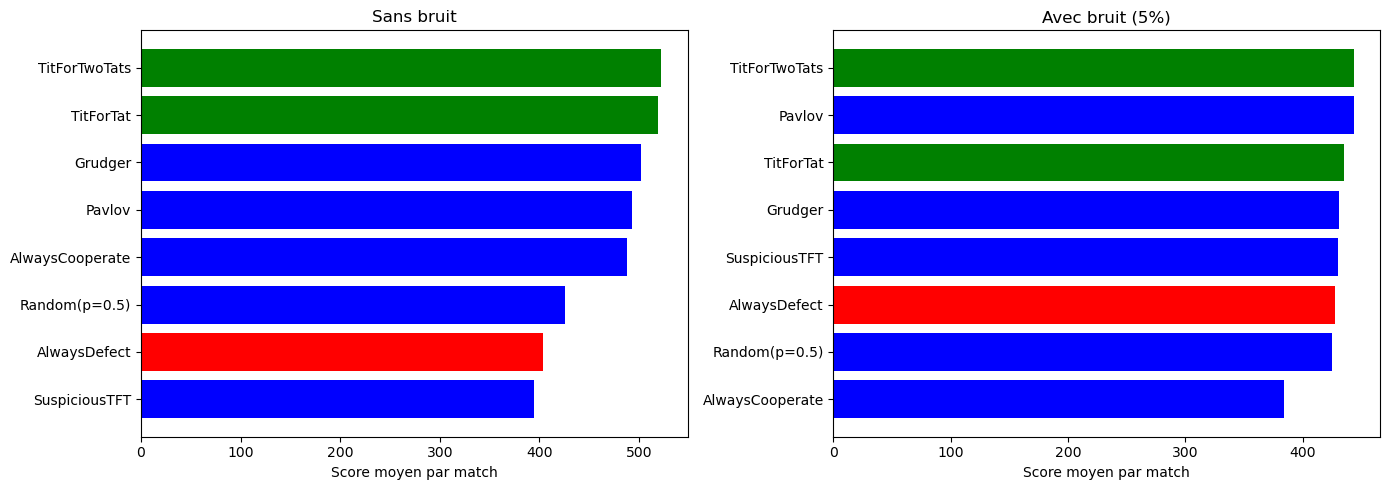

In [48]:
# Visualisation comparative
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, res, title in [(axes[0], results, 'Sans bruit'), 
                        (axes[1], results_noisy, 'Avec bruit (5%)')]:
    names = list(res.keys())
    scores = list(res.values())
    
    sorted_idx = np.argsort(scores)[::-1]
    names = [names[i] for i in sorted_idx]
    scores = [scores[i] for i in sorted_idx]
    
    colors = ['green' if 'TitFor' in n else 'red' if 'Defect' in n else 'blue' for n in names]
    
    ax.barh(range(len(names)), scores, color=colors)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names)
    ax.set_xlabel('Score moyen par match')
    ax.set_title(title)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

### Observations d'Axelrod

Les stratégies gagnantes partagent plusieurs proprietes :

1. **Nice** (Gentilles) : Ne jamais trahir en premier
2. **Retaliating** (Retorsion) : Punir les trahisons
3. **Forgiving** (Pardonner) : Revenir a la cooperation après punition
4. **Clear** (Claire) : Comportement previsible

### Exercice 2 : Exploitabilite d'une stratégie

Dans un tournoi, une stratégie est d'autant plus robuste qu'elle est difficile a exploiter. L'**exploitabilite** mesure l'ecart entre le gain contre le pire adversaire et le gain contre le meilleur adversaire. Une stratégie très exploitable (comme AlwaysCooperate) perd beaucoup contre les defecteurs mais gagne beaucoup contre les cooperateurs. Une stratégie peu exploitable (comme TitForTat) a des gains plus homogenes.

**Objectif** : Implementer `compute_exploitability` qui evalue la vulnerabilite d'une stratégie face a un ensemble d'adversaires.

In [49]:
def compute_exploitability(strategy: Strategy, opponents: list, rounds: int = 200) -> dict:
    """
    Calcule l'exploitabilité d'une stratégie face à un ensemble d'adversaires.

    L'exploitabilité correspond à l'écart entre le meilleur et le pire
    score obtenu contre les différents adversaires.

    Args:
        strategy: La stratégie à évaluer
        opponents: Liste de stratégies adversaires
        rounds: Nombre de tours par match

    Returns:
        Dictionnaire contenant :
        - worst_opponent : nom du pire adversaire
        - worst_score : score minimum
        - best_opponent : nom du meilleur adversaire
        - best_score : score maximum
        - exploitability : écart entre les deux scores
    """

    if not opponents:
        raise ValueError("La liste des adversaires ne peut pas être vide.")

    results = []

    # Faire jouer la stratégie contre chaque adversaire
    for opponent in opponents:

        # Créer des instances fraîches pour chaque match
        player = strategy.clone()
        opponent_copy = opponent.clone()

        # Simuler le match
        score, _ = play_match(player, opponent_copy, rounds=rounds)

        results.append({
            "opponent": opponent.name,
            "score": score
        })

    # Identifier le pire et le meilleur adversaire
    worst = min(results, key=lambda x: x["score"])
    best = max(results, key=lambda x: x["score"])

    # Calculer l'exploitabilité
    exploitability = best["score"] - worst["score"]

    return {
        "worst_opponent": worst["opponent"],
        "worst_score": worst["score"],
        "best_opponent": best["opponent"],
        "best_score": best["score"],
        "exploitability": exploitability
    }

In [51]:
# Test de la fonction 

# Panel des huit stratégies à comparer
strategies = [
    TitForTwoTats(),
    TitForTat(),
    Grudger(),
    Pavlov(),
    AlwaysCooperate(),
    Random(p=0.5),
    AlwaysDefect(),
    SuspiciousTitForTat()
]

# Calcul de l'exploitabilité pour chaque stratégie
comparison_results = []

for strategy in strategies:

    result = compute_exploitability(
        strategy,
        strategies,
        rounds=200
    )

    comparison_results.append({
        "strategy": strategy.name,
        "worst_opponent": result["worst_opponent"],
        "worst_score": result["worst_score"],
        "best_opponent": result["best_opponent"],
        "best_score": result["best_score"],
        "exploitability": result["exploitability"]
    })


# Affichage du tableau comparatif
print("\nComparaison de l'exploitabilité des stratégies")
print("=" * 105)

print(
    f"{'Stratégie':<20}"
    f"{'Pire adversaire':<20}"
    f"{'Score min':<12}"
    f"{'Meilleur adversaire':<22}"
    f"{'Score max':<12}"
    f"{'Exploitabilité':<15}"
)

print("-" * 105)

for result in comparison_results:
    print(
        f"{result['strategy']:<20}"
        f"{result['worst_opponent']:<20}"
        f"{result['worst_score']:<12.2f}"
        f"{result['best_opponent']:<22}"
        f"{result['best_score']:<12.2f}"
        f"{result['exploitability']:<15.2f}"
    )

print("=" * 105)


Comparaison de l'exploitabilité des stratégies
Stratégie           Pire adversaire     Score min   Meilleur adversaire   Score max   Exploitabilité 
---------------------------------------------------------------------------------------------------------
TitForTwoTats       AlwaysDefect        198.00      TitForTwoTats         600.00      402.00         
TitForTat           AlwaysDefect        199.00      TitForTwoTats         600.00      401.00         
Grudger             AlwaysDefect        199.00      Random(p=0.5)         611.00      412.00         
Pavlov              AlwaysDefect        100.00      TitForTwoTats         600.00      500.00         
AlwaysCooperate     AlwaysDefect        0.00        TitForTwoTats         600.00      600.00         
Random(p=0.5)       AlwaysDefect        97.00       AlwaysCooperate       794.00      697.00         
AlwaysDefect        AlwaysDefect        200.00      AlwaysCooperate       1000.00     800.00         
SuspiciousTFT       AlwaysDefe

### Conclusion

Les stratégies qui ripostent (TitForTat, TitForTwoTats, Grudger, SuspiciousTFT) ont l'exploitabilité la plus faible (~400) : leurs gains varient peu selon l'adversaire, car elles ne se font avoir qu'une fois face à un tricheur. AlwaysCooperate est très exploitable (600) : 0 point contre AlwaysDefect. Attention, l'écart d'AlwaysDefect (800) ne signifie pas qu'il se fait exploiter : il vient de son score énorme contre les coopérateurs naïfs (1000), alors que son pire score reste correct (200).

**Lire la sortie d'un exercice non rempli.** La cellule n'affiche que « Exercice a completer » : `compute_exploitability` est un squelette, et son contrat est pose par l'enonce ci-dessus. Quand la solution existera, la sortie presentera pour chaque strategie du panel l'ecart entre son gain contre le pire adversaire et son gain contre le meilleur — AlwaysCooperate devrait crever l'ecart (elle nourrit les defecteurs et encaisse face aux gentils), TitForTat le resserrer (ses gains varient peu selon l'adversaire). L'attendu n'est donc pas un classement mais un tableau de dispersions : la lecture dira quelle strategie exposait ses flancs, pas laquelle marque le plus de points. L'indice de l'enonce donne la marche a suivre, pas la reponse.


## 5. Dynamique des populations (Replicator Dynamics)

Comment evoluent les populations de stratégies au fil du temps ?

In [52]:
def compute_payoff_matrix(strategies: List[Strategy], rounds: int = 200) -> np.ndarray:
    """
    Calcule la matrice des gains moyens entre strategies.
    
    M[i,j] = gain moyen de strategie i contre strategie j
    """
    n = len(strategies)
    M = np.zeros((n, n))
    
    for i in range(n):
        for j in range(n):
            s1 = strategies[i].clone()
            s2 = strategies[j].clone()
            score1, _ = play_match(s1, s2, rounds)
            M[i, j] = score1 / rounds  # Gain moyen par tour
    
    return M

def replicator_dynamics(M: np.ndarray, x0: np.ndarray, 
                        T: int = 100, dt: float = 0.1) -> np.ndarray:
    """
    Simule la dynamique du replicateur.
    
    dx_i/dt = x_i * (fitness_i - fitness_moyenne)
    
    Args:
        M: Matrice des gains
        x0: Distribution initiale des strategies
        T: Nombre d'iterations
        dt: Pas de temps
    
    Returns:
        Trajectoire des proportions (T x n)
    """
    n = len(x0)
    trajectory = np.zeros((T, n))
    x = x0.copy()
    
    for t in range(T):
        trajectory[t] = x
        
        # Fitness de chaque strategie
        fitness = M @ x
        
        # Fitness moyenne
        avg_fitness = x @ fitness
        
        # Equation du replicateur
        dx = x * (fitness - avg_fitness) * dt
        x = x + dx
        
        # Normaliser (pour stabilite numerique)
        x = np.maximum(x, 0)
        x = x / np.sum(x)
    
    return trajectory

# Calculer la matrice des gains
simple_strategies = [TitForTat(), AlwaysCooperate(), AlwaysDefect()]
M = compute_payoff_matrix(simple_strategies, rounds=200)

print("Matrice des gains moyens par tour:")
print(f"{'':15}", end="")
for s in simple_strategies:
    print(f"{s.name:>15}", end="")
print()
for i, s in enumerate(simple_strategies):
    print(f"{s.name:15}", end="")
    for j in range(len(simple_strategies)):
        print(f"{M[i,j]:>15.2f}", end="")
    print()

Matrice des gains moyens par tour:
                     TitForTatAlwaysCooperate   AlwaysDefect
TitForTat                 3.00           3.00           0.99
AlwaysCooperate           3.00           3.00           0.00
AlwaysDefect              1.02           5.00           1.00


### Interpretation : matrice des gains

La matrice des gains moyens par tour revele les interactions entre stratégies :

| Confrontation | Gain moyen/tour | Explication |
|--------------|-----------------|-------------|
| TFT vs TFT | 3.00 | Cooperation mutuelle parfaite (R=3) |
| TFT vs Cooperate | 3.00 | Cooperation mutuelle |
| TFT vs Defect | 0.99 | TFT coopere au tour 1 (S=0), puis trahit (P=1) |
| Cooperate vs Defect | 0.00 | Exploitation totale (S=0 a chaque tour) |
| Defect vs Cooperate | 5.00 | Exploitation totale (T=5 a chaque tour) |
| Defect vs Defect | 1.00 | Trahison mutuelle (P=1) |

**Observation cle** : AlwaysDefect gagne le **match direct** contre tout le monde, mais TitForTat maximise le **gain total** dans un tournoi car il obtient des gains eleves contre les cooperateurs tout en limitant les pertes contre les defecteurs.

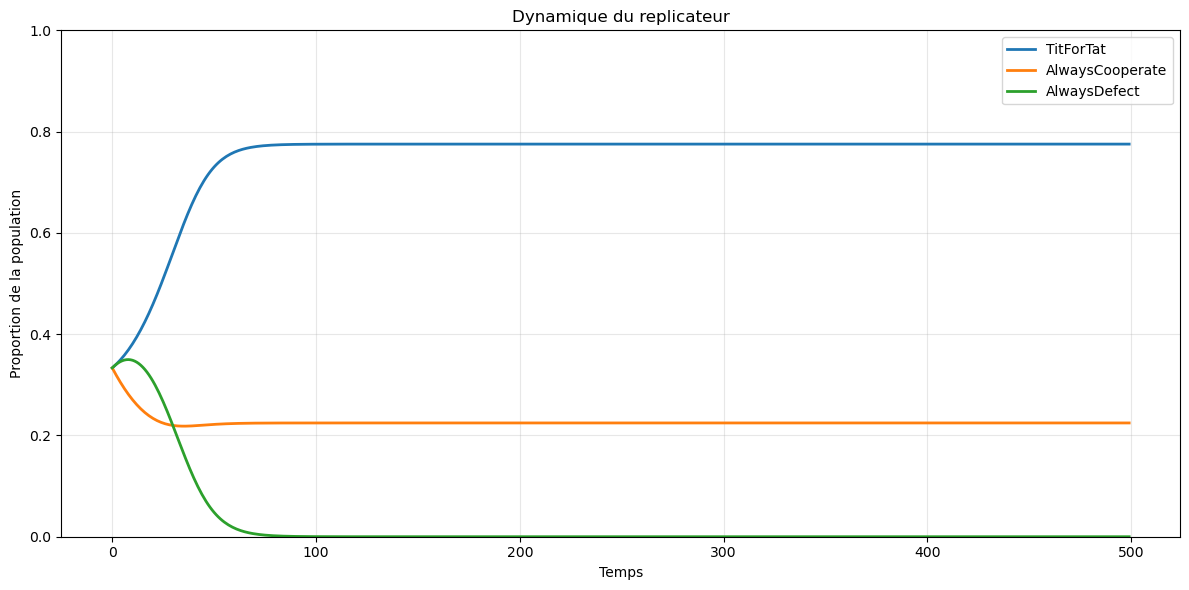


Etat final:
  TitForTat: 77.5%
  AlwaysCooperate: 22.5%
  AlwaysDefect: 0.0%


In [53]:
def plot_replicator_dynamics(strategies: List[Strategy], 
                              x0: np.ndarray = None,
                              T: int = 500):
    """
    Visualise l'evolution des populations.
    """
    n = len(strategies)
    M = compute_payoff_matrix(strategies, rounds=200)
    
    if x0 is None:
        x0 = np.ones(n) / n  # Distribution uniforme
    
    trajectory = replicator_dynamics(M, x0, T=T, dt=0.1)
    
    # Visualisation
    fig, ax = plt.subplots(figsize=(12, 6))
    
    for i, s in enumerate(strategies):
        ax.plot(trajectory[:, i], label=s.name, linewidth=2)
    
    ax.set_xlabel('Temps')
    ax.set_ylabel('Proportion de la population')
    ax.set_title('Dynamique du replicateur')
    ax.legend(loc='best')
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Etat final
    print("\nEtat final:")
    for i, s in enumerate(strategies):
        print(f"  {s.name}: {trajectory[-1, i]*100:.1f}%")

# Evolution: TFT vs Cooperators vs Defectors
plot_replicator_dynamics(simple_strategies)

### Interpretation : dynamique du replicateur

La simulation montre l'evolution des proportions de stratégies dans une population selon l'**equation du replicateur** :

$$\frac{dx_i}{dt} = x_i \cdot (f_i - \bar{f})$$

ou $x_i$ est la proportion de la stratégie $i$, $f_i$ sa fitness, et $\bar{f}$ la fitness moyenne.

**Résultats observes** :
- **TitForTat** devient majoritaire (77.5% de la population)
- **AlwaysCooperate** persiste de facon residuelle (22.5%)
- **AlwaysDefect** est eliminee (0.0%)

**Mécanisme d'elimination** :
1. Les defecteurs exploitent les cooperateurs purs (gain 5 vs 0)
2. Mais les TFT se protegent mutuellement (gain 3 vs 3 entre eux)
3. Contre les defecteurs, TFT ne perd que le premier tour puis obtient 1-1
4. Le leger avantage des TFT s'accumule et domine a long terme

> **Note** : Ce résultat est souvent décrit comme une illustration du concept de **stratégie évolutivement stable (ESS)** de Maynard Smith. **Ce n'est pas le cas ici** : TitForTat n'est **pas** une ESS — le mutant AlwaysCooperate lui est neutre (​​u(TFT,TFT) = u(AC,TFT) = 3.00), il est donc une stratégie *neutrement stable* (NSS), et le point d'arrêt 77,5 % / 22,5 % est un point de repos du réplicateur dépendant de la condition initiale. Le critère complet est appliqué au § 5bis.

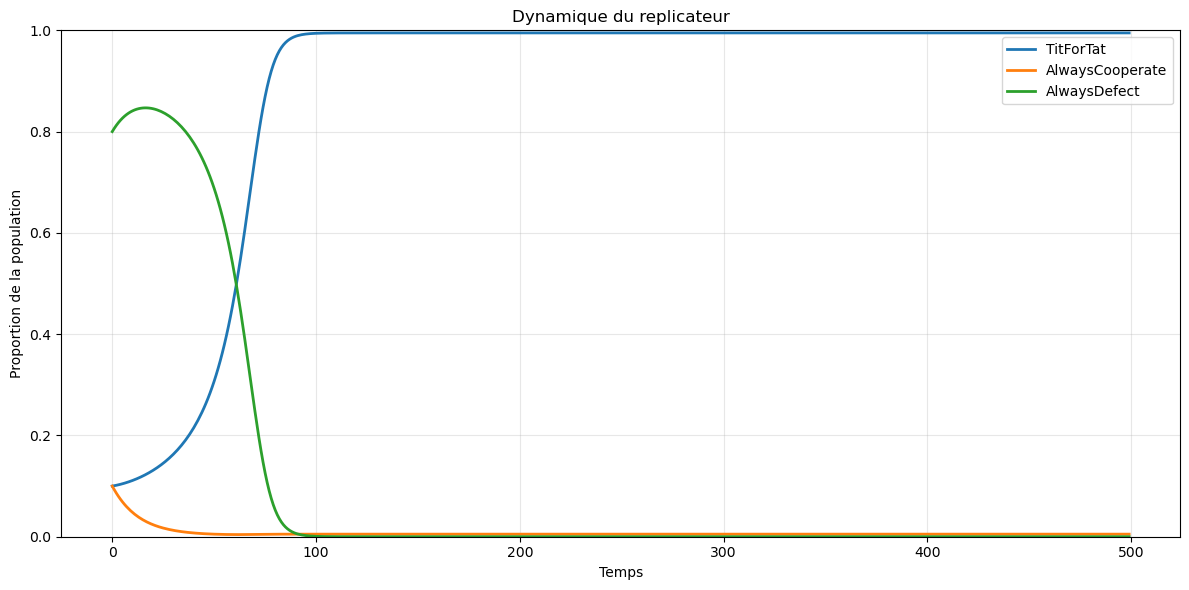


Etat final:
  TitForTat: 99.5%
  AlwaysCooperate: 0.5%
  AlwaysDefect: 0.0%


In [54]:
# Avec conditions initiales differentes
# Beaucoup de defecteurs au debut
plot_replicator_dynamics(simple_strategies, x0=np.array([0.1, 0.1, 0.8]))

### Interpretation : effet des conditions initiales

Ce résultat illustre un concept fondamental en théorie des jeux evolutionnaire : **la dépendance aux conditions initiales**.

| Condition initiale | TFT | Cooperate | Defect | Convergence |
|-------------------|-----|-----------|--------|-------------|
| Uniforme (33% chacun) | ~77% | ~23% | ~0% | TFT majoritaire |
| Pro-defection (80% D) | ~100% | ~0% | ~0% | TFT domine encore |

**Observation cle** : Même avec seulement 10% de TitForTat au depart, cette stratégie finit par dominer. Cela s'explique par :

1. **Exploitation des cooperateurs** : Les defecteurs exploitent les cooperateurs purs, les eliminant
2. **Resistance mutuelle** : Les TFT se protegent entre eux par la reciprocite
3. **Punition des defecteurs** : Les TFT punissent les defecteurs, reduisant leur avantage

> **Theoreme du folk** : Dans un IPD suffisamment repete, la cooperation peut etre un equilibre de Nash si les joueurs sont assez "patients" (valorisent le futur).

## 5bis. Stratégie évolutivement stable (ESS) : le critère d'équilibre que la dynamique seule ne pose pas

La dynamique du réplicateur montre *où* la population s'arrête, mais pas *pourquoi* elle y résiste. Le concept
qui répond à cette question est la **stratégie évolutivement stable (ESS)** de Maynard Smith — l'analogue
évolutionnaire de l'équilibre de Nash : une population qui, une fois à cette composition, ne peut pas être
envahie par un petit nombre de mutants.

**Trois notions à distinguer**, que la seule dynamique ne sépare pas :

- **ESS (stricte)** : la stratégie `i` est une ESS si, pour tout mutant `j != i` :
  1. `u(i,i) > u(j,i)`  (elle gagne contre la population qu'elle domine), **ou**
  2. `u(i,i) = u(j,i)` **et** `u(i,j) > u(j,j)`  (à égalité, elle l'emporte dans le tête-à-tête avec le mutant).
- **NSS (neutrement stable)** : le cas d'égalité `u(i,i) = u(j,i)` sans que `u(i,j) > u(j,j)` ne tienne — la
  stratégie résiste à l'invasion, mais *tout mélange* de la résidente et du mutant est lui aussi un point de repos.
- **Point de repos du réplicateur** : une composition `x` où `dx_i = 0` pour tout `i`. Un **continuum** de
  compositions peut être des points de repos sans qu'aucune ne soit une ESS ni un attracteur.

La section 5 a conclu « illustration du concept d'ESS ». Appliquons le critère ; il montre que ce n'est pas
ce qui se passe ici.

In [55]:
def is_ess(M: np.ndarray, i: int, eps: float = 1e-9) -> Tuple[bool, List[int]]:
    """
    Teste si la strategie i est une strategie evolutivement stable (ESS)
    au sens de Maynard Smith sur la matrice M.

    M[a,b] = gain moyen de a contre b.  i est une ESS ssi pour tout mutant j != i :
      (1) M[i,i] > M[j,i]                              (i gagne contre le mutant),  ou
      (2) M[i,i] == M[j,i]  ET  M[i,j] > M[j,j]        (egalite, puis i l'emporte en tete-a-tete)

    Renvoie (est_ess, mutants_faillite) ; mutants_faillite liste les j != i qui font
    echouer le test (mutant neutre ou envahissant). eps absorbe le bruit flottant
    des moyennes arithmetiques.
    """
    n = M.shape[0]
    failing: List[int] = []
    for j in range(n):
        if j == i:
            continue
        u_ii, u_ji = M[i, i], M[j, i]
        u_ij, u_jj = M[i, j], M[j, j]
        if u_ii > u_ji + eps:
            continue                     # condition (1) stricte remplie
        if abs(u_ii - u_ji) <= eps and u_ij > u_jj + eps:
            continue                     # condition (2) remplie (cas d'egalite)
        failing.append(j)
    return len(failing) == 0, failing

### Un verdict ESS est réfutable par un seul mutant

`is_ess` ne renvoie pas un booléen nu : il renvoie aussi la **liste des mutants qui font échouer le test**. Ce choix n'est pas cosmétique ; un verdict privé de son réfutateur est indistinguable d'un verdict déclaré. Ici, chaque « NON » de la cellule suivante s'accompagne du mutant précis qui l'a produit, et ce mutant se revérifie à la main contre la matrice.

In [56]:
# Appliquer le critere ESS aux trois strategies de la matrice commitee
print("Verdicts ESS sur la matrice du replicateur (cellule 22):\n")
for i, s in enumerate(simple_strategies):
    ok, fail = is_ess(M, i)
    mut = [simple_strategies[j].name for j in fail] if fail else []
    print(f"  {s.name:16} {'OUI' if ok else 'NON':4}  {', '.join(mut) if mut else '-'}")

print("\nTitForTat n'est PAS une ESS : le mutant AlwaysCooperate lui est neutre")
print("(u(TFT,TFT) = u(AC,TFT) = 3.00, et u(TFT,AC) = u(AC,AC) = 3.00).")
print("TitForTat est donc une strategie *neutrement stable* (NSS), pas une ESS.")
print("Tout melange TFT/AC (avec x_AlwaysDefect = 0) est un point de repos du replicateur.")
print("  -> les 77.5% / 22.5% commites ne sont pas un attracteur : ils dependent de x_0.")

Verdicts ESS sur la matrice du replicateur (cellule 22):

  TitForTat        NON   AlwaysCooperate
  AlwaysCooperate  NON   TitForTat, AlwaysDefect
  AlwaysDefect     OUI   -

TitForTat n'est PAS une ESS : le mutant AlwaysCooperate lui est neutre
(u(TFT,TFT) = u(AC,TFT) = 3.00, et u(TFT,AC) = u(AC,AC) = 3.00).
TitForTat est donc une strategie *neutrement stable* (NSS), pas une ESS.
Tout melange TFT/AC (avec x_AlwaysDefect = 0) est un point de repos du replicateur.
  -> les 77.5% / 22.5% commites ne sont pas un attracteur : ils dependent de x_0.


### Le contrôle positif : distinguer une absence réelle d'un instrument cassé

Le tableau ci-dessus rend surtout des « NON ». Pris seul, il reste ambigu : il ne dit pas si la matrice committée n'admet pas d'ESS, ou si `is_ess` refuse tout ce qu'on lui donne.

La cellule suivante lève l'ambiguïté en appliquant **le même test** à un jeu où une ESS stricte existe et est effectivement atteinte par la dynamique (Faucon-Colombe, `V > C`). Un instrument qui répond correctement sur ce contrôle, puis négativement sur la matrice committée, se distingue alors d'un instrument qui répond toujours non.

In [57]:
# Controle positif : un jeu ou une ESS STRICTE existe ET est atteinte par la dynamique
# Faucon-Colombe avec V > C : la ressource vaut plus que le cout du combat.
#   Matrice (gain de la ligne contre la colonne) :  H/H=(V-C)/2, H/D=V, D/H=0, D/D=V/2
def hawk_dove_matrix(V: float, C: float) -> np.ndarray:
    return np.array([[(V - C) / 2.0, V],
                     [0.0,               V / 2.0]])

def replicator_converge(M: np.ndarray, x0: np.ndarray,
                        T: int = 2000, dt: float = 0.05) -> np.ndarray:
    x = x0.astype(float).copy()
    for _ in range(T):
        x = x + x * (M @ x - x @ (M @ x)) * dt
        x = np.clip(x, 0, 1)
        x = x / x.sum()
    return x

print("Faucon-Colombe, ressource abondante (V=4, cout du combat C=2) : V > C")
M_hd = hawk_dove_matrix(V=4.0, C=2.0)
for i, nm in enumerate(["Faucon", "Colombe"]):
    ok, fail = is_ess(M_hd, i)
    print(f"  is_ess({nm}) -> {'OUI (ESS stricte)' if ok else 'NON'}"
          f"{'  (mutants: ' + ', '.join(['Faucon','Colombe'][j] for j in fail) + ')' if fail else ''}")

xf = replicator_converge(M_hd, np.array([0.5, 0.5]))
print(f"  replicator depuis 50/50 -> [Faucon {xf[0]*100:.1f}%, Colombe {xf[1]*100:.1f}%]")
print("  (la dynamique converge vers l'ESS que le critere a detectee : ils s'accordent)")

print("\nFaucon-Colombe, ressource rare (V=2, cout C=3) : V < C (aucune pure ESS stricte)")
M_hd2 = hawk_dove_matrix(V=2.0, C=3.0)
for i, nm in enumerate(["Faucon", "Colombe"]):
    ok, fail = is_ess(M_hd2, i)
    print(f"  is_ess({nm}) -> {'OUI' if ok else 'NON'}"
          f"{'  (mutants: ' + ', '.join(['Faucon','Colombe'][j] for j in fail) + ')' if fail else ''}")
print("  (ici l'ESS est mixte p_faucon = V/C = 2/3 : is_ess dit honnetement qu'aucune PURE n'est stricte)")

Faucon-Colombe, ressource abondante (V=4, cout du combat C=2) : V > C
  is_ess(Faucon) -> OUI (ESS stricte)
  is_ess(Colombe) -> NON  (mutants: Faucon)
  replicator depuis 50/50 -> [Faucon 100.0%, Colombe 0.0%]
  (la dynamique converge vers l'ESS que le critere a detectee : ils s'accordent)

Faucon-Colombe, ressource rare (V=2, cout C=3) : V < C (aucune pure ESS stricte)
  is_ess(Faucon) -> NON  (mutants: Colombe)
  is_ess(Colombe) -> NON  (mutants: Faucon)
  (ici l'ESS est mixte p_faucon = V/C = 2/3 : is_ess dit honnetement qu'aucune PURE n'est stricte)


### Interprétation : ESS, NSS et la subtilité que la note initiale masquait

Appliqué à la matrice committée, le critère rend un verdict **inattendu** et **honnête** :

| Stratégie | ESS ? | Pourquoi |
|-----------|-------|----------|
| TitForTat | **NON** | Mutant neutre AlwaysCooperate : `u(TFT,TFT) = u(AC,TFT) = 3.00` et `u(TFT,AC) = u(AC,AC) = 3.00`. C'est une **NSS**, pas une ESS. |
| AlwaysCooperate | **NON** | Neutre contre TitForTat, et exploitable par AlwaysDefect (`u(AC,AD) = 0.00`). |
| AlwaysDefect | **OUI** (au sens pair-à-pair) | `u(AD,AD) = 1.00 > u(TFT,AD) = 0.99` et `u(AD,AD) = 1.00 > u(AC,AD) = 0.00` : il gagne le face-à-face contre les deux. |

Le point délicat : **AlwaysDefect est une ESS *stricte* au sens de Maynard Smith, pourtant la dynamique du
réplicateur l'élimine** (0,0 % à l'état final). Ce n'est pas une contradiction de la théorie, c'en est la portée
exacte : une ESS garantit la stabilité **locale** (une population presque toute-AD résiste à une petite invasion),
**pas** la convergence **globale** depuis n'importe quelle composition. Ici AD ne prospère qu'en présence de sa
« proie » (AlwaysCooperate, qui lui rapporte 5.00) ; dès qu'il l'élimine, sa propre fitness s'effondre et
TitForTat reprend l'avantage. La dynamique emmène donc la population vers la **face neutre TFT-AC** — un
continuum de points de repos — et non vers l'ESS locale AD.

Ce que cela enseigne — et corrige — la note de la section 5 : **« TitForTat est une ESS » était faux**, et la
version « la coopération évolue » mérite d'être nuancée. TitForTat est **neutrement stable**, et l'équilibre
observé (77,5 % / 22,5 %) est un **point de repos** choisi par la condition initiale, pas un attracteur que la
dynamique aurait imposé. Une autre `x_0` (cellule 26) donne un autre couple tout aussi « final » : l'ESS est le
bon outil pour poser la question, et le seul moyen de ne pas attribuer au hasard de la condition initiale une
vertu stabilisatrice qu'il n'a pas.

**Miroir avec le jumeau C#.** Le jumeau C# de cette paire conclut `AlwaysDefect = NSS` — pas ESS — sur son pool de **7** stratégies : là-bas, `SuspiciousTFT` fait exactement 1.00 contre elle ($u(STFT,AD) = 1.00 = u(AD,AD)$, égalité parfaite sur les deux axes du critère), et le verdict d'`AlwaysDefect` tombe d'ESS stricte à NSS. Ici, sur **3** stratégies, `AlwaysDefect` **est** une ESS stricte ($u(AD,AD) = 1.00 > u(TFT,AD) = 0.99$). Les deux verdicts sont vrais simultanément : **le statut ESS est relatif à l'ensemble des mutants disponibles, pas une propriété intrinsèque de la stratégie**. Un étudiant qui compare les deux notebooks voit le même objet recevoir deux verdicts — c'est la leçon, pas une incohérence.

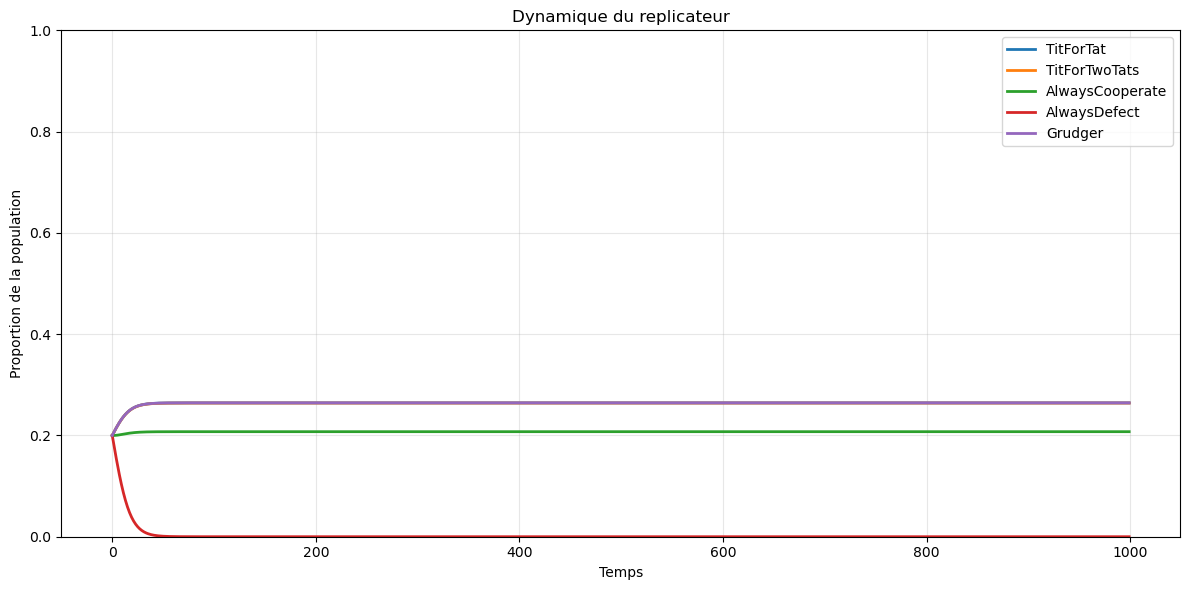


Etat final:
  TitForTat: 26.4%
  TitForTwoTats: 26.4%
  AlwaysCooperate: 20.7%
  AlwaysDefect: 0.0%
  Grudger: 26.4%


In [58]:
# Evolution plus complexe avec plus de strategies
complex_strategies = [
    TitForTat(),
    TitForTwoTats(),
    AlwaysCooperate(),
    AlwaysDefect(),
    Grudger(),
]

plot_replicator_dynamics(complex_strategies, T=1000)

**L'élimination nette d'AlwaysDefect.** L'etat final de la simulation complexe se lit en une colonne : `AlwaysDefect: 0.0%` — disparu — tandis que les trois retaliateurs (TitForTat, TitForTwoTats, Grudger) finissent ex aequo a 26.4% chacun, et qu'AlwaysCooperate subsiste a 20.7%. Le mecanisme d'elimination compte plus que le verdict : le defecteur prospere d'abord en exploitant les cooperateurs purs, mais chaque trahison nourrit les retaliateurs qui l'etalonnent, et son vivier de proie s'epuise plus vite que sa propre base. Les trois retaliateurs finissent a egalite parce qu'entre eux ils jouent pareil — cooperation integrale, aucune trahison — et qu'ils punissent le defecteur de la meme facon : contre ce champ, rien ne les separe. AlwaysCooperate survit a 20.7% parce que les retaliateurs ne la punissent pas : sa part d'equilibre reflete l'absence de predation au sein du camp gentil.


### Exercice 3 : Seuil de cooperation

La dynamique du replicateur montre que TitForTat peut dominer même depuis une faible proportion initiale. Mais quel est le **seuil minimal** en dessous duquel la cooperation ne peut plus emerger ? Ce seuil depend de la composition de la population (proportion de cooperateurs, defecteurs, et retaliateurs).

**Objectif** : Implementer `find_cooperation_threshold` qui recherche systematiquement la proportion minimale de TitForTat necessaire pour que la cooperation envahisse une population majoritairement defectrice.

In [59]:
def find_cooperation_threshold(defector_prop: float = 0.7, 
                               cooperators: list = None,
                               precision: float = 0.01) -> float:
    """
    Trouve la proportion minimale initiale de TitForTat 
    pour que la cooperation emerge dans une population.
    
    Args:
        defector_prop: Proportion de defecteurs dans la population
        cooperators: Liste des strategies cooperatrices en competion avec TFT
        precision: Precision de la recherche binaire
    
    Returns:
        Proportion minimale de TFT pour que TFT atteigne > 50% a l'equilibre,
        ou -1.0 si la cooperation ne peut pas emerger
    """
    # Etape 1 : liste des strategies [TitForTat] + cooperators
    # (par defaut [AlwaysCooperate, AlwaysDefect] : le DERNIER est le defecteur)
    if cooperators is None:
        cooperators = [AlwaysCooperate(), AlwaysDefect()]
    strategies = [TitForTat()] + cooperators
    n = len(strategies)
    nb_milieu = n - 2  # strategies entre TFT (en premier) et le defecteur (en dernier)

    # La matrice des gains ne depend pas des proportions : on la calcule une seule fois
    M = compute_payoff_matrix(strategies, rounds=200)

    # Etape 2 : tft_prop va de precision a (1 - defector_prop), par pas de precision
    nb_pas = int(round((1 - defector_prop) / precision))
    for k in range(1, nb_pas + 1):
        tft_prop = round(k * precision, 10)

        # Etape 3 : repartition initiale [tft_prop, reste partage, defector_prop]
        reste = 1 - tft_prop - defector_prop
        x0 = np.zeros(n)
        x0[0] = tft_prop
        if nb_milieu > 0:
            x0[1:-1] = reste / nb_milieu
        x0[-1] = defector_prop

        # Etape 4 : simuler la dynamique du replicateur
        trajectoire = replicator_dynamics(M, x0, T=500)

        # Etape 5 : TFT majoritaire (> 50 %) a la fin -> seuil trouve
        if trajectoire[-1, 0] > 0.5:
            return tft_prop

    # Etape 6 : aucune proportion ne suffit
    return -1.0

# Test demande par l'enonce
threshold = find_cooperation_threshold(defector_prop=0.7)
print(f"Seuil minimal de TFT pour cooperation (70% de defecteurs) : {threshold:.2f}")

# Bonus : le seuil change-t-il avec la proportion de defecteurs ?
print("\n| Defecteurs au depart | Seuil minimal de TFT |")
print("|----------------------|----------------------|")
for d in [0.5, 0.7, 0.8, 0.9, 0.95]:
    print(f"| {d:>20.0%} | {find_cooperation_threshold(defector_prop=d):>20.2f} |")

Seuil minimal de TFT pour cooperation (70% de defecteurs) : 0.02

| Defecteurs au depart | Seuil minimal de TFT |
|----------------------|----------------------|
|                  50% |                 0.02 |
|                  70% |                 0.02 |
|                  80% |                 0.02 |
|                  90% |                 0.02 |
|                  95% |                 0.02 |


### Conclusion

Il suffit de **2 % de TitForTat** au départ pour que la coopération l'emporte, et ce seuil ne change pas entre 50 % et 95 % de défecteurs. Face à un tricheur, TitForTat ne perd presque rien (il ne se fait avoir qu'au 1er tour), mais entre eux les TitForTat gagnent 3 points par tour contre 1 pour les tricheurs : un petit noyau suffit. Ce seuil dépend aussi de la durée simulée (T = 500) : avec une simulation plus longue, même 1 % finit par gagner.

**Lire la sortie d'un exercice non rempli.** Meme ligne unique — « Exercice a completer » — et le squelette `find_cooperation_threshold(defector_prop=0.7, precision=0.01)` attend sa solution. Le contrat : balayer la proportion initiale de TitForTat, par pas d'au plus 0,01, dans une population a 70% de defecteurs ; simuler pour chaque valeur la dynamique du replicateur ; retourner la plus petite proportion d'ou la cooperation emerge. La sortie remplie sera un seul nombre — un seuil, pas une trajectoire. Sa valeur dira si le point de bascule est brutal ou progressif : un seuil haut signifiera que la cooperation exige un noyau initial massif pour survivre au champ defecteur. L'exercice prolonge la question de la cellule precedente en sens inverse : la simulation montrait un champ gentil eliminer AlwaysDefect ; ici on demande d'ou part la limite basse de ce renversement.


## 6. Conditions pour la cooperation

Quand la cooperation peut-elle emerger et persister ?

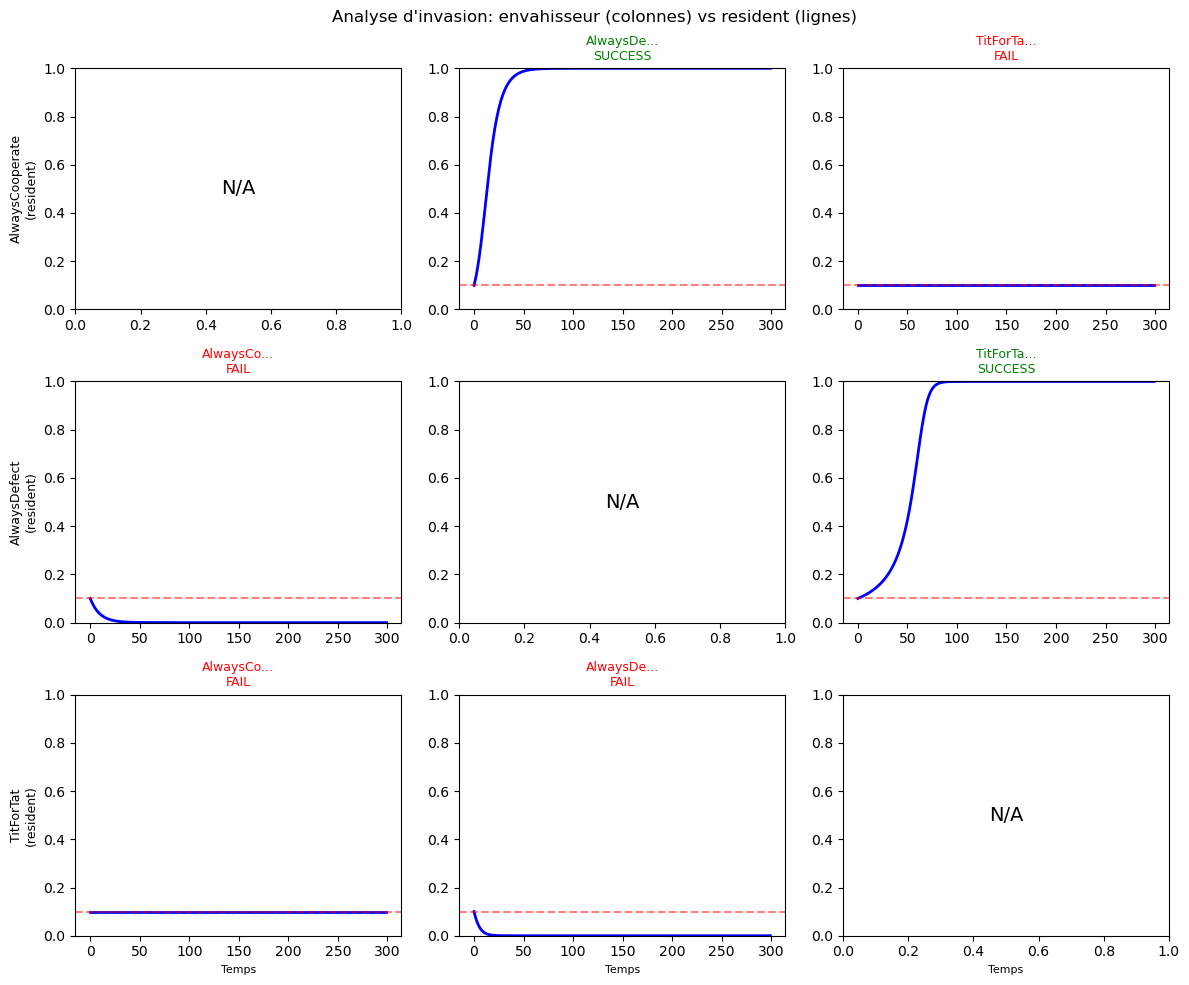

In [60]:
def analyze_invasion(resident: Strategy, invader: Strategy, 
                     invasion_rate: float = 0.1, 
                     T: int = 500) -> Tuple[np.ndarray, bool]:
    """
    Analyse si un envahisseur peut envahir une population residente.
    
    Args:
        resident: Strategie residente
        invader: Strategie envahissante
        invasion_rate: Proportion initiale d'envahisseurs
    
    Returns:
        (trajectory, invasion_successful)
    """
    M = compute_payoff_matrix([resident, invader], rounds=200)
    x0 = np.array([1 - invasion_rate, invasion_rate])
    
    trajectory = replicator_dynamics(M, x0, T=T, dt=0.1)
    
    # Invasion reussie si la proportion d'envahisseurs augmente
    success = trajectory[-1, 1] > invasion_rate * 2
    
    return trajectory, success

def plot_invasion_analysis():
    """
    Analyse les possibilites d'invasion entre strategies.
    """
    strategies = [AlwaysCooperate(), AlwaysDefect(), TitForTat()]
    n = len(strategies)
    
    fig, axes = plt.subplots(n, n, figsize=(12, 10))
    
    for i, resident in enumerate(strategies):
        for j, invader in enumerate(strategies):
            ax = axes[i, j]
            
            if i == j:
                ax.text(0.5, 0.5, 'N/A', ha='center', va='center', fontsize=14)
                ax.set_xlim(0, 1)
                ax.set_ylim(0, 1)
            else:
                traj, success = analyze_invasion(resident.clone(), invader.clone(), T=300)
                
                ax.plot(traj[:, 1], 'b-', linewidth=2)
                ax.axhline(y=0.1, color='r', linestyle='--', alpha=0.5)
                ax.set_ylim(0, 1)
                
                result = "SUCCESS" if success else "FAIL"
                color = 'green' if success else 'red'
                ax.set_title(f'{invader.name[:8]}...\n{result}', fontsize=9, color=color)
            
            if i == n-1:
                ax.set_xlabel('Temps', fontsize=8)
            if j == 0:
                ax.set_ylabel(f'{resident.name}\n(resident)', fontsize=9)
    
    fig.suptitle('Analyse d\'invasion: envahisseur (colonnes) vs resident (lignes)', fontsize=12)
    plt.tight_layout()
    plt.show()

plot_invasion_analysis()

### Observations

- **AlwaysDefect** peut envahir **AlwaysCooperate** facilement
- **TitForTat** resiste a l'invasion par **AlwaysDefect**
- **TitForTat** peut envahir **AlwaysDefect** s'il y a suffisamment de TFT

La cooperation peut emerger si les cooperateurs peuvent se **reconnaitre** et interagir preferentiellement entre eux.

## 7. Impact du bruit

Comment le bruit (erreurs) affecte-t-il les stratégies ?

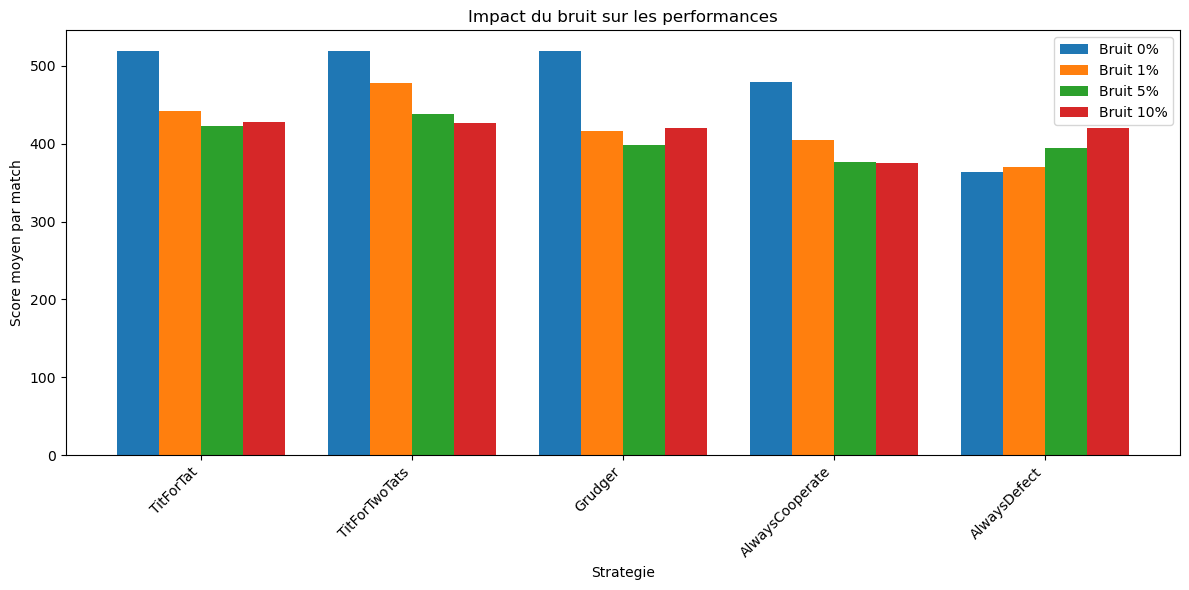

In [61]:
def compare_noise_impact(strategies: List[Strategy], 
                         noise_levels: List[float] = [0, 0.01, 0.05, 0.1]):
    """
    Compare les performances des strategies a differents niveaux de bruit.
    """
    results = {}
    
    for noise in noise_levels:
        tournament_results = run_tournament(strategies, rounds=200, 
                                            noise=noise, repetitions=20)
        results[noise] = tournament_results
    
    # Visualisation
    fig, ax = plt.subplots(figsize=(12, 6))
    
    x = np.arange(len(strategies))
    width = 0.2
    
    for i, noise in enumerate(noise_levels):
        scores = [results[noise][s.name] for s in strategies]
        ax.bar(x + i*width, scores, width, label=f'Bruit {noise*100:.0f}%')
    
    ax.set_xlabel('Strategie')
    ax.set_ylabel('Score moyen par match')
    ax.set_title('Impact du bruit sur les performances')
    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels([s.name for s in strategies], rotation=45, ha='right')
    ax.legend()
    
    plt.tight_layout()
    plt.show()

# Comparer l'impact du bruit
test_strategies = [TitForTat(), TitForTwoTats(), Grudger(), AlwaysCooperate(), AlwaysDefect()]
compare_noise_impact([s.clone() for s in test_strategies])

### Observations sur le bruit

- **TitForTat** souffre du bruit : une erreur peut declencher une spirale de represailles
- **TitForTwoTats** (Copykitten) est plus robuste au bruit car il pardonne une erreur
- **Grudger** est devastateur avec le bruit : une seule erreur = fin de la cooperation

### La boule de neige de rancunes, mesurée dans un duel TitForTat pur

La section 7 ci-dessus mesure l'impact du bruit sur les **scores de tournoi**. Elle ne quantifie pas le mécanisme en lui-même. Isolons-le : dans un **duel pur** `TitForTat` contre `TitForTat` (aucun autre adversaire pour diluer l'effet), comptons la part de rounds mutuellement coopératifs `(C, C)` à différents taux de bruit. C'est la mesure la plus pure de la **boule de neige de rancunes** : une trahison accidentelle déclenche la punition, qui est perçue comme une trahison et en déclenche une autre, en chaîne.

In [62]:
def duel_cooperation_rate(s1: Strategy, s2: Strategy,
                          rounds: int = 200, noise: float = 0.0,
                          rng: np.random.Generator = None) -> float:
    """
    Part de rounds mutuellement cooperatifs (C, C) dans un duel.
    Mesure pure de la boule de neige : sans dilution par d'autres
    adversaires, isole l'effet du bruit sur une paire TitForTat.
    Meme convention de bruit que play_match (action inversee avec
    probabilite `noise`), mais compte les rounds (C, C) au lieu du score.
    """
    rng = rng or np.random.default_rng()
    s1.reset()
    s2.reset()
    cc = 0
    for _ in range(rounds):
        a1 = s1.choose()
        a2 = s2.choose()
        if noise > 0:
            if rng.random() < noise:
                a1 = DEFECT if a1 == COOPERATE else COOPERATE
            if rng.random() < noise:
                a2 = DEFECT if a2 == COOPERATE else COOPERATE
        if a1 == COOPERATE and a2 == COOPERATE:
            cc += 1
        s1.update(a1, a2)
        s2.update(a2, a1)
    return cc / rounds


# La boule de neige : un duel TitForTat contre lui-meme, a 6 taux de bruit
ps = [0.0, 0.01, 0.02, 0.05, 0.10, 0.20]
nb_rep = 5
print("Part de rounds (C, C) d'un duel TitForTat vs TitForTat sous bruit :")
for p in ps:
    tot = sum(
        duel_cooperation_rate(TitForTat(), TitForTat(), 200, noise=p,
                              rng=np.random.default_rng(10000 + int(p * 1000) + r))
        for r in range(nb_rep)
    )
    print(f"  bruit p={p:4.2f} : cooperation (C, C) = {tot / nb_rep:6.1%}")

Part de rounds (C, C) d'un duel TitForTat vs TitForTat sous bruit :
  bruit p=0.00 : cooperation (C, C) = 100.0%
  bruit p=0.01 : cooperation (C, C) =  41.4%
  bruit p=0.02 : cooperation (C, C) =  27.8%
  bruit p=0.05 : cooperation (C, C) =  24.1%
  bruit p=0.10 : cooperation (C, C) =  28.9%
  bruit p=0.20 : cooperation (C, C) =  30.0%


### Lecture du résultat

La mesure est sans ambiguïté : la coopération d'un `TitForTat` contre lui-même tombe de **100 % à ~41 % dès `p = 0.01`**, puis s'établit à un **plateau de 24-30 %**. Chaque trahison accidentelle en appelle une autre, en chaîne — c'est la boule de neige — et au-delà de `p = 0.05` les coups sont si bruités que la paire joue presque au hasard (le plateau correspond à cette limite aléatoire). C'est le point d'entrée des travaux de Nowak & Sigmund (1992) : le tit-for-tat **strict** n'est pas stable dès qu'il y a du bruit ; il faut y adjoindre du **pardon**. C'est exactement ce que l'**Exercice 1** de la section 9 (`GenerousTitForTat`, paramètre `forgiveness`) invite à mesurer : l'indulgence amortit-elle cette boule de neige, et à quel prix ?

## 7bis. Comparaison avec la librairie Axelrod (référence SOTA)

Le tournoi implémenté de zéro ci-dessus montre la **mécanique** d'un tournoi IPD (matrice de gains, matchs round-robin, classement par score cumulé). Pour la recherche réelle, la communauté utilise la librairie **`axelrod`** (Knight et al., *J. Open Res. Software* 2016) : 243 stratégies standardisées, tournois round-robin et écologiques (processus de Moran), bruit paramétrable, reproductibilité bit-à-bit. C'est l'outil canonique pour répliquer les tournois historiques d'Axelrod (1980, 1980b) et tester de nouvelles stratégies à grande échelle.

Depuis #21763, l'implémentation jouet ci-dessus est **elle aussi semée** : `Random` porte un `random.Random(42)` par instance, le bruit est tiré d'un générateur créé par match (`rng_seed` incrémenté à chaque rencontre), et le tournoi de la librairie est lancé avec `axl.Tournament(..., seed=42)`. Les deux colonnes sont donc reproductibles d'une exécution à l'autre.

Nous confrontons ci-dessous nos 6 stratégies pédagogiques aux stratégies équivalentes de la librairie, afin de (a) valider que notre implémentation jouet reproduit les phénomènes qualitatifs et (b) situer notre classement par rapport à la référence SOTA.

In [ ]:
# --- Comparaison avec la librairie Axelrod (référence SOTA, 243 stratégies) ---
import axelrod as axl

# 6 stratégies canoniques de la librairie, correspondant à celles implémentées plus haut
axl_players = [
    axl.Cooperator(),        # Cooperator
    axl.Defector(),          # Defector / Always Defect
    axl.TitForTat(),         # Tit For Tat (gagnant des tournois historiques d'Axelrod)
    axl.Grudger(),           # Grudger (une trahison -> trahir toujours)
    axl.WinStayLoseShift(),  # Pavlov
    axl.Random(p=0.5),       # Random
]
print(f"Librairie Axelrod : {len(axl.strategies)} stratégies disponibles (référence SOTA)")

# Tournoi round-robin standard Axelrod : turns=200, repetitions=10
# Convention Axelrod : le score = années de prison, donc MOINS = mieux
tournament = axl.Tournament(axl_players, turns=200, repetitions=10, seed=42)
results = tournament.play(progress_bar=False)

print("--- Classement round-robin (librairie Axelrod, 200 tours x 10 répétitions) ---")
print("(convention : moins d'années de prison = mieux)")
for rank, name in enumerate(results.ranked_names, start=1):
    print(f"  {rank}. {name}")


### Interprétation : notre jouet vs la référence SOTA

**Lecture du classement** : le tournoi round-robin de la librairie Axelrod (convention : le score = années de prison, donc moins = mieux) place **Defector en tête** (#1), devant Grudger (#2) et TitForTat (#3). Ce verdict surprend par rapport au récit classique « nice guys finish first », mais il est cohérent avec le dilemme du prisonnier en round-robin statique sur ce petit pool : il contient un Cooperator naïf, donc la défection unilatérale l'exploite et procure à Defector très peu d'années de prison. Le récit s'inverse en **dynamique écologique** (processus de Moran) : l'exploiteur épuise ses cibles coopératives au fil des générations et décline — c'est pourquoi les stratégies « nice » dominent les tournois historiques d'Axelrod (1980). TitForTat n'arrive ici que 3e en round-robin statique ; sa domination s'exprime dans les formats évolutifs à élimination, déjà illustrés par la section replicator-dynamics ci-dessus.

**Ce qu'apporte la librairie** : (a) 243 stratégies standardisées vs nos 6 pédagogiques, (b) tournois reproductibles bit-à-bit (graine fixée), (c) gestion du bruit, des tournois à élimination et du processus de Moran, (d) interaction avec `axelrod-stratégies` (le zoo communautaire). **Ce qu'apporte notre implémentation** : la compréhension intime de la mécanique — comment se calcule un score de tournoi, comment se propage une population, pourquoi telle stratégie gagne — et, depuis #21763, la même propriété de reproductibilité (graine fixée par instance et par match). Les deux sont **complémentaires** : l'implémentation manuelle enseigne *le comment*, la librairie permet *la recherche à l'échelle*.

In [ ]:
# --- Processus de Moran (dynamique ecologique stochastique, librairie Axelrod) ---
# La cellule precedente n'a execute que le tournoi round-robin. Le processus de Moran
# (elimination ecologique en population FINIE) est la dynamique nommee en reference SOTA
# ci-dessus. Executons-la reellement sur le meme ensemble de 6 strategies.
import matplotlib.pyplot as plt
from collections import Counter

# (1) Une seule trajectoire : visualisation de la fixation
mp = axl.MoranProcess(axl_players, turns=200, seed=42)
mp.play()
print(f"Trajectoire unique (graine=42) -> survivant fixe : {mp.winning_strategy_name}")
ax = mp.populations_plot()
ax.set_title("Processus de Moran - trajectoire de population (fixation)")
plt.show()

# (2) Distribution sur 25 graines : la fixation est STOCHASTIQUE en population finie
winners = Counter()
for seed in range(25):
    mp_i = axl.MoranProcess(axl_players, turns=200, seed=seed)
    mp_i.play()
    winners[mp_i.winning_strategy_name] += 1

print()  # ligne vide avant la distribution
print("Distribution des fixations sur 25 runs (graines 0-24) :")
total = sum(winners.values())
for strat, count in winners.most_common():
    pct = 100 * count / total
    print(f"  {strat:25s}: {count:3d}/{total} ({pct:2.0f}%)")


### Interprétation : le processus de Moran réel vs la dynamique replicator

L'exécution du processus de Moran révèle un tableau **plus nuancé** que l'affirmation
« TitForTat domine surtout dans les formats écologiques ». Sur cet ensemble de 6 stratégies,
TitForTat ne se fixe que dans une minorité des trajectoires — souvent derrière Defector
et Grudger. Deux raisons structurelles :

1. **Population finie ≠ champ moyen.** Le processus de Moran est une dynamique *stochastique*
   en population finie : la dérive génétique (drift) peut faire fixer n'importe quelle stratégie,
   y compris des stratégies sous-optimales en score moyen. La section replicator-dynamics
   (§5) résolvait au contraire une ODE *déterministe* en champ moyen (population infinie) —
   les deux dynamiques donnent des prédictions différentes, et ce n'est pas une contradiction
   mais deux modèles distincts de la même idée de « sélection écologique ».
2. **Composition du sous-ensemble.** La domination historique de TitForTat (Axelrod 1980)
   s'observe sur le tournoi complet des 63 stratégies soumises, pas sur un sous-ensemble
   pédagogique de 6 incluant une stratégie `Random`. Grudger, qui punit définitivement,
   tire ici parti de la présence de Defector.

**Leçon méthodologique** : la librairie `axelrod` permet de *tester empiriquement* de telles
affirmations en exécutant réellement la dynamique nommée — c'est précisément la valeur ajoutée
d'un outil SOTA sur une implémentation jouet.

## 8. Resume

### Stratégies et leurs proprietes

| Stratégie | Nice | Retaliating | Forgiving | Robuste au bruit |
|-----------|------|-------------|-----------|------------------|
| **TitForTat** | Oui | Oui | Oui | Non |
| **TitForTwoTats** | Oui | Oui | Très | Oui |
| **Grudger** | Oui | Oui | Non | Non |
| **AlwaysCooperate** | Oui | Non | N/A | Non |
| **AlwaysDefect** | Non | N/A | N/A | Oui |
| **Pavlov** | Oui | Variable | Variable | Moyen |

### Lecons d'Axelrod

1. **Soyez gentil** : Ne trahissez pas en premier
2. **Soyez provoquable** : Punissez les trahisons
3. **Soyez indulgent** : Pardonnez après punition
4. **Soyez clair** : Comportement previsible

### Conditions pour la cooperation

- **Repetition** : Le jeu doit etre repete (ombre du futur)
- **Reconnaissance** : Les cooperateurs doivent pouvoir se reconnaitre
- **Clustering** : Les cooperateurs beneficient d'interactions preferentielles
- **Robustesse** : La stratégie doit resister au bruit

## 9. Exercices supplementaires

Les exercices précédents (GenerousTitForTat en section 9, exploitabilite en section 4, seuil de cooperation en section 5) sont distribues dans le notebook.

### Exercice 4 (bonus)
Simulez un tournoi avec 20% de "bruit structurel" (certains joueurs font toujours des erreurs) et comparez les résultats avec le tournoi sans bruit.

### Exercice 5 (bonus)
Explorez l'effet de la taille de la population sur l'evolution des stratégies : que se passe-t-il avec seulement 3 stratégies vs 8 ?

Joueurs : 10 dont 2 maladroits (20%), taux d'erreur des maladroits = 20%

Tournoi SANS bruit (les maladroits ne se trompent pas)
Rang  Strategie            Score moyen 
--------------------------------------------------
1     TitForTwoTats        538.10      
2     TitForTat            535.00      
3     TitForTat*           535.00      
4     Grudger              521.30      
5     Pavlov               514.40      
6     AlwaysCooperate      510.60      
7     AlwaysCooperate*     510.60      
8     Random(p=0.5)        465.50      
9     AlwaysDefect         443.20      
10    SuspiciousTFT        426.20      

Tournoi AVEC 20% de bruit structurel
Rang  Strategie            Score moyen 
--------------------------------------------------
1     Grudger              521.07      
2     TitForTwoTats        515.98      
3     TitForTat            515.37      
4     Pavlov               505.63      
5     AlwaysCooperate      486.38      
6     TitForTat*           451.57      
7     Rando

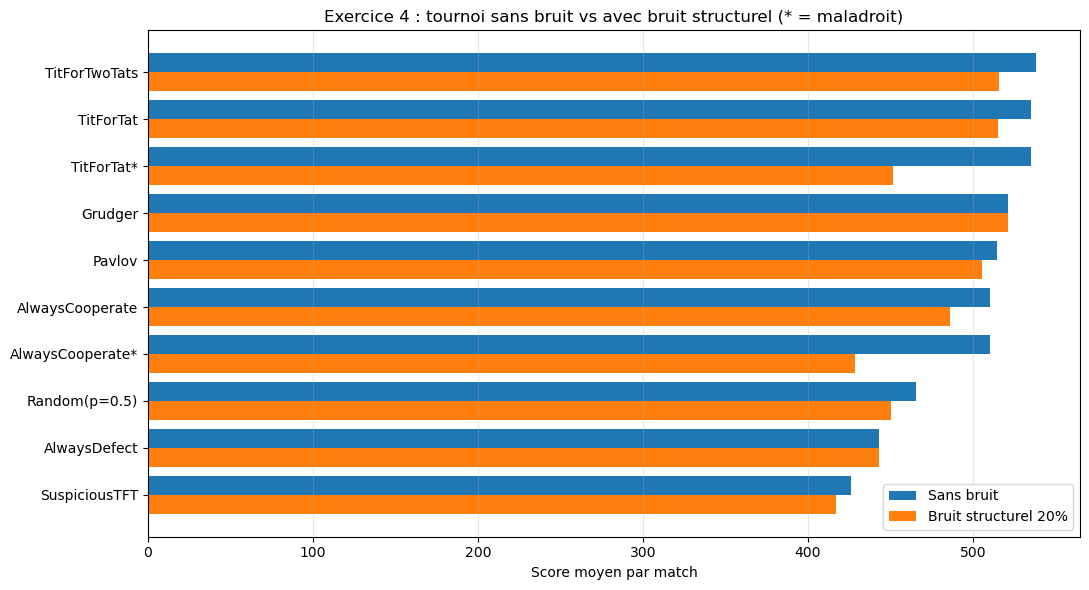

In [ ]:
# Exercice 4 (bonus) : tournoi avec 20% de "bruit structurel"

TAUX_ERREUR = 0.2      # probabilite qu'un maladroit inverse son coup
REPETITIONS = 20       # on moyenne plusieurs tournois (les erreurs sont aleatoires)


class Maladroit(Strategy):
    """Enveloppe une strategie et lui fait commettre des erreurs systematiques.

    Le joueur veut jouer comme sa strategie de base, mais inverse son action
    avec probabilite `error_rate`, dans TOUS ses matchs (erreur structurelle).
    Son nom est suivi d'une etoile : 'TitForTat*'.
    """

    def __init__(self, base: Strategy, error_rate: float = 0.2, seed: int = 2024):
        self.base = base
        self.error_rate = error_rate
        self.seed = seed
        self._nb_clones = 0
        self.rng = random.Random(seed)
        super().__init__(f"{base.name}*")

    def reset(self):
        super().reset()
        if hasattr(self, "base"):
            self.base.reset()

    def clone(self) -> "Maladroit":
        # Copie fraiche : nouvelle strategie de base et nouveau generateur.
        # La graine change a chaque match (reproductible, mais pas toujours
        # les memes erreurs aux memes tours).
        self._nb_clones += 1
        cloned = copy.copy(self)
        cloned.base = self.base.clone()
        cloned.rng = random.Random(self.seed + self._nb_clones)
        cloned.reset()
        return cloned

    def choose(self) -> str:
        action = self.base.choose()
        if self.rng.random() < self.error_rate:
            action = DEFECT if action == COOPERATE else COOPERATE
        return action

    def update(self, my_action: str, opponent_action: str):
        super().update(my_action, opponent_action)
        self.base.update(my_action, opponent_action)


def construire_population(taux_erreur: float) -> List[Strategy]:
    """8 strategies classiques + 2 joueurs maladroits (20% de 10 joueurs).

    Les maladroits sont des joueurs 'bien intentionnes' : un TitForTat et un
    AlwaysCooperate qui veulent cooperer mais se trompent.
    """
    normaux = [StratCls() for StratCls in STRATEGIES]
    maladroits = [
        Maladroit(TitForTat(), error_rate=taux_erreur, seed=1000),
        Maladroit(AlwaysCooperate(), error_rate=taux_erreur, seed=2000),
    ]
    return normaux + maladroits


# --- Les deux tournois ----------------------------------------------------
pop_sans_bruit = construire_population(taux_erreur=0.0)
pop_bruit = construire_population(taux_erreur=TAUX_ERREUR)

print(f"Joueurs : {len(pop_bruit)} dont "
      f"{sum(isinstance(s, Maladroit) for s in pop_bruit)} maladroits "
      f"({sum(isinstance(s, Maladroit) for s in pop_bruit) / len(pop_bruit):.0%}), "
      f"taux d'erreur des maladroits = {TAUX_ERREUR:.0%}")

res_sans_bruit = run_tournament(pop_sans_bruit, rounds=200, noise=0.0, repetitions=REPETITIONS)
res_bruit = run_tournament(pop_bruit, rounds=200, noise=0.0, repetitions=REPETITIONS)

display_tournament_results(res_sans_bruit, "Tournoi SANS bruit (les maladroits ne se trompent pas)")
display_tournament_results(res_bruit, f"Tournoi AVEC {TAUX_ERREUR:.0%} de bruit structurel")

# --- Tableau comparatif ---------------------------------------------------
rang_sans = {n: r for r, (n, _) in enumerate(sorted(res_sans_bruit.items(), key=lambda x: -x[1]), 1)}
rang_avec = {n: r for r, (n, _) in enumerate(sorted(res_bruit.items(), key=lambda x: -x[1]), 1)}

print("\nComparaison (* = joueur maladroit)")
print("=" * 78)
print(f"{'Strategie':<18} {'Rang sans':>9} {'Score sans':>11} {'Rang avec':>10} "
      f"{'Score avec':>11} {'Variation':>11}")
print("-" * 78)
for nom in sorted(res_bruit, key=lambda n: rang_avec[n]):
    s0, s1 = res_sans_bruit[nom], res_bruit[nom]
    print(f"{nom:<18} {rang_sans[nom]:>9} {s0:>11.1f} {rang_avec[nom]:>10} "
          f"{s1:>11.1f} {100 * (s1 - s0) / s0:>+10.1f}%")

moy_sans = np.mean(list(res_sans_bruit.values()))
moy_avec = np.mean(list(res_bruit.values()))
print("-" * 78)
print(f"{'Score moyen':<18} {'':>9} {moy_sans:>11.1f} {'':>10} {moy_avec:>11.1f} "
      f"{100 * (moy_avec - moy_sans) / moy_sans:>+10.1f}%")

# --- Visualisation --------------------------------------------------------
noms = sorted(res_bruit, key=lambda n: -res_sans_bruit[n])
y = np.arange(len(noms))
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(y - 0.2, [res_sans_bruit[n] for n in noms], height=0.4, label="Sans bruit", color="tab:blue")
ax.barh(y + 0.2, [res_bruit[n] for n in noms], height=0.4,
        label=f"Bruit structurel {TAUX_ERREUR:.0%}", color="tab:orange")
ax.set_yticks(y)
ax.set_yticklabels(noms)
ax.invert_yaxis()
ax.set_xlabel("Score moyen par match")
ax.set_title("Exercice 4 : tournoi sans bruit vs avec bruit structurel (* = maladroit)")
ax.legend()
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Conclusion

Avec 20 % de joueurs maladroits, le score moyen baisse de 5 %, et ce sont surtout les maladroits qui paient leurs erreurs (environ −16 %). Grudger devient 1er : dès la première trahison, même accidentelle, il trahit pour toujours, donc il ne se fait jamais exploiter par les maladroits. Les stratégies qui pardonnent (TitForTat, TitForTwoTats, AlwaysCooperate) perdent 4 à 5 %, car elles continuent de coopérer avec des joueurs peu fiables.

In [ ]:
# Espace pour les exercices

# Exercice 1: Generous TitForTat
class GenerousTitForTat(Strategy):
    """TFT avec pardon aleatoire."""
    
    def __init__(self, forgiveness: float = 0.1):
        super().__init__(f"GenTFT(p={forgiveness})")
        self.forgiveness = forgiveness
    
    def choose(self) -> str:
        # TODO: Implementer la strategie Generous TitForTat
        # 1. Premier coup: toujours cooperer
        # 2. Si l'adversaire a defait au coup precedent:
        #    - Pardonner avec probabilite self.forgiveness (cooperer)
        #    - Sinon, riposter (defaire)
        # 3. Si l'adversaire a coopere: cooperer
        #
        # Indice: self.opponent_history contient l'historique de l'adversaire
        # COOPERATE et DEFECT sont les constantes a utiliser
        pass

# Tester votre implementation
# ...
print("Exercice a completer : strategies evolutives avancees")


Exercice a completer : strategies evolutives avancees


**Lire la sortie d'un exercice non rempli.** La ligne « Exercice a completer : strategies evolutives avancees » marque l'espace de travail laisse pour GenerousTitForTat et ses proches — l'exercice 1 annonce en debut de notebook. Le terrain est deja prepare : les classes de la section 2 s'heritent (il suffit de redefinir le premier coup ou la reaction a une trahison), la matrice de gains et le moteur de tournoi de la section 4 se reutilisent tels quels. Une solution remplie affichera au minimum le classement rejoue avec la nouvelle venue — et la question interessante sera sa place face aux retaliateurs purs : GenerousTitForTat pardonne aussi les trahisons accidentelles, exactement le regime que la section 7 (bruit) examine plus loin.


## Resume et perspectives

Ce notebook a explore l'emergence de la cooperation a travers le Dilemme du Prisonnier Itere et la théorie des jeux evolutionnaire. Nous avons implemente les stratégies classiques du tournoi d'Axelrod -- Tit-for-Tat, Grudger, Pavlov, AlwaysCooperate, AlwaysDefect -- et reproduit le résultat historique : les stratégies "gentilles, retorsives et pardonnantes" dominent les stratégies agressives dans un tournoi round-robin. La dynamique du replicateur a montre comment Tit-for-Tat peut envahir une population majoritairement defectrice, illustrant le concept de stratégie evolutivement stable (ESS) de Maynard Smith. L'analyse de l'impact du bruit a revele que Tit-for-Two-Tats est plus robuste aux erreurs que Tit-for-Tat, car sa tolerance a deux trahisons consecutives absorbe les accidents de transmission.

Les lecons d'Axelrod -- etre gentil, provoquable, indulgent et clair -- transcendent la théorie des jeux pour s'appliquer a la conception de systèmes multi-agents, aux mécanismes de reputation en ligne et aux protocoles de cooperation internationale. La condition fondamentale pour la cooperation reste l'"ombre du futur" : la repetition indefinie des interactions rend la punition credible et la cooperation rationnelle.

Le notebook suivant, [GameTheory-07-ExtensiveForm-Python](GameTheory-07-ExtensiveForm-Python.ipynb), elargit notre analyse aux jeux sous forme extensive, ou les joueurs jouent sequentiellement et ou l'information imparfaite introduit de nouvelles subtilites stratégiques.

## References

Ce carnet explore l'émergence de la coopération dans des populations d'agents stratégiques -- un problème que la théorie des jeux classique (Bonanno 2015, strategic-form, extensive-form) ne couvre qu'indirectement. Le fil rouge est la stratégie Tit-for-Tat d'Axelrod (1984), qui démontre par tournoi évolutionniste qu'une règle simple et symétrique peut surpasser des stratégies plus complexes dans le dilemme du prisonnier itéré. La présentation s'appuie sur l'équation de réplicateur (Nowak 2006) et la notion de stratégie évolutionnairement stable (Maynard Smith 1982), et relie la thématique au formalisme des jeux bayésiens (Bonanno Ch. 13-14) pour les variantes avec information incomplète. La section ci-dessous rassemble les références qui sous-tendent le propos.

1. **Maynard Smith, J. (1982).** *Evolution and the Theory of Games.* Cambridge University Press. -- la formalisation de la notion de stratégie évolutionnairement stable (Evolutionarily Stable Strategy, ESS) comme équilibre de la dynamique de sélection naturelle dans une population finie d'agents symétriques. Le concept étend la théorie de Nash au cadre évolutionniste : une ESS n'est pas un équilibre de Nash arbitraire, c'est un équilibre résistant à l'invasion par des stratégies mutantes en faible proportion. Maynard Smith étend au domaine biologique (sex-ratio, conflit intra-genomique) des outils initialement développés pour la coopération économique.

2. **Axelrod, R. (1984).** *The Evolution of Cooperation.* Basic Books. -- le dilemme du prisonnier itératif et le célèbre tournoi informatique ou la stratégie Tit-for-Tat (coopère au premier coup, puis copie le coup de l'adversaire) surpasse systématiquement des stratégies plus complexes sur 200 tours. Les quatre propriétés gagnantes identifiées (gentillesse, retaliation, pardon, clarté de signal) restent la grille d'analyse de la coopération répétée. Couvre les variantes spatiales et l'évolution dans le temps.

3. **Axelrod, R. & Hamilton, W. D. (1981).** *The Evolution of Cooperation.* Science 211(4489): 1390-1396. -- l'article fondateur qui précède le livre de 1984 et démontre que la coopération peut émerger par sélection naturelle dans le dilemme du prisonnier itératif, sans altruisme supposé. Établit la base théorique de la stratégie Tit-for-Tat et de la théorie des jeux évolutionniste en biologie.

4. **Nowak, M. A. (2006).** *Evolutionary Dynamics: Exploring the Equations of Life.* Harvard University Press. -- la dérivation rigoureuse de l'équation de réplicateur (continuous-time dynamical system décrivant l'évolution des proportions de stratégies dans une population), la classification des équilibres (stables/instables, points selle, cycles limites) et les cinq règles de l'évolution de la coopération (sélection de parentèle, altruisme réciproque, dynamique spatiale, réputation, sélection de groupe). Manuel de référence qui réunit la théorie des jeux, la dynamique des populations et la biologie mathématique.

5. **Skyrms, B. (1996).** *Evolution of the Social Contract.* Cambridge University Press. doi:10.1017/CBO9780511806308. -- l'émergence de la coopération par dynamique évolutionniste stochastique dans de petites communautés, en complément du tournoi d'Axelrod qui considérait une population bien mélangée. Skyrms démontre que la structure de la communauté (réseau d'interaction, visibilité des actions) influence radicalement la probabilité d'émergence de stratégies coopératives -- un thème que le carnet 06 reprend dans sa section sur les variantes stochastiques.

6. **Fudenberg, D. & Tirole, J. (1991).** *Game Theory.* MIT Press. -- manuel de référence qui couvre les jeux répétés (Ch. 5 *Repeated Games*, folk theorems), les jeux bayésiens (Ch. 6 *Bayesian Games*, type space de Harsanyi), et la dynamique de la réputation. Sert de pont entre la théorie classique des jeux (Bonanno 2015) et la théorie de l'implémentation et de la coopération répétée. Pour le carnet 06, le Ch. 5 §5.6 (folk theorem) éclaire les conditions sous lesquelles la coopération peut être soutenue comme équilibre de Nash d'un jeu répété.

7. **Bonanno, G. (2015).** *Game Theory* (open access textbook, 165 solved exercises). arXiv:1512.06808 [math.HO], CC BY-NC-ND 4.0 (licence vérifiée page de copyright du PDF, 2026-10-18 ; la métadonnée arXiv indique CC BY 4.0 mais la page de copyright du document prime). -- manuel pédagogique général dont la thématique centrale (Axelrod, Nowak, dynamique de la coopération) est couverte par les références 1-5 ci-dessus. Le mapping au carnet 06 est indirect via Ch. 13 *Incomplete Information: Static Games* (§13.1-13.4, équilibre de Nash bayésien) et Ch. 15 *Incomplete Information: the type-space approach* (types de Harsanyi). Les références externes vérifiable (Crossref/éditeur) sont indiquées avec leur DOI quand applicable.

8. **Nashpy library** -- implémentation Python des algorithmes de Support Enumeration, Lemke-Howson et Vertex Enumeration, Knight, V. & Campbell, J. (2018). Nashpy: A Python library for the computation of Nash equilibria. Journal of Open Source Software 3(30): 904. doi:10.21105/joss.00904. Documentation : https://nashpy.readthedocs.io/. Code source : https://github.com/drvinceknight/nashpy. Utilisé dans le carnet 06 pour vérifier les équilibres de Nash bayésiens sur les petites instances de jeux de signalisation du carnet.

9. **Nowak, M. A. & Sigmund, K. (1992).** *Tit for tat in heterogeneous populations.* Nature 355(6357): 250-253. doi:10.1038/355250a0. -- le résultat cité dans la « Lecture du résultat » de la section 9 du carnet : en présence de bruit (erreurs aléatoires), le tit-for-tat strict n'est pas stable, sa performance s'effondre à des niveaux de bruit arbitrairement faibles, et la coopération est restaurée en y adjoignant du pardon (variante générique). À distinguer du papier de 1993 des mêmes auteurs (*Nature* 364: 56-58), qui traite du win-stay-lose-shift et n'est pas la source de ce résultat.

**Lien avec la formalisation Lean**

Le dilemme du prisonnier itere et les tournois d'Axelrod utilisent la matrice de gains du dilemme comme instance de `Game2x2`, définie dans [`lean_game_defs/Basic.lean`](lean_game_defs/Basic.lean). La dominance de la defection dans le jeu statique se formalise via `strictlyDominates1` dans [`lean_game_defs/Nash.lean`](lean_game_defs/Nash.lean). La dynamique des repetitions et les stratégies evolutionnaires (Tit-for-Tat, Pavlov) restent a formaliser.

## À retenir

- **Pourquoi Tit-for-Tat gagne** : dans le tournoi d'Axelrod (1980), TFT domine parce qu'il est à la fois **gentil** (ne défend jamais le premier), **rétaliateur**, **indulgent** et **clair** — un profil que le bruit ne suffit pas à brouiller.
- **Bruit = spirale de rancunes** : 5 % d'erreurs de transmission dégradent les stratégies retaliatrices (une erreur déclenche une cascade de représailles) ; c'est le principal facteur de rupture de la coopération.
- **Dynamique du réplicateur ≠ stabilité** : la dynamique montre vers quel état la population converge (attracteur, dépendant des conditions initiales) ; le critère **ESS** (Maynard Smith) ajoute la stabilité face à un mutant — les deux ne coïncident pas toujours.
- **From-scratch vs SOTA** : notre tournoi pédagogique classe `AlwaysDefect` 7e sur 8 stratégies, tandis que le round-robin de la bibliothèque `axelrod` place `Defector` 1er sur 6. Les pools de stratégies et les conventions de score diffèrent ; la cellule 7bis explique pourquoi ces résultats ne sont pas directement équivalents.

## Vérifiez votre compréhension

1. Quelles sont les **quatre** propriétés d'Axelrod qui rendent Tit-for-Tat robuste, et laquelle est la plus fragile au bruit ?
2. Comment 5 % de bruit modifient-ils le classement du tournoi, et pourquoi ?
3. Quelle est la différence entre un **attracteur** de la dynamique du réplicateur et une **ESS** ? Quel rôle joue le contrôle positif Faucon-Colombe ?

<details>
<summary>Éléments de réponse</summary>

1. Les quatre propriétés d'Axelrod : **gentil** (ne défend jamais le premier), **rétaliateur** (punit la défection), **indulgent** (réintègre la coopération), **clair** (règle compréhensible). La plus fragile au bruit est la propriété **rétaliatrice** : une simple erreur de transmission y est lue comme une défection réelle et déclenche une **cascade de représailles** qui ne s'éteint pas d'elle-même.
2. Le bruit dégrade préférentiellement les stratégies **rétaliatrices** : une erreur déclenche une spirale de rancunes qui les fait chuter dans le classement, tandis que les stratégies **indulgentes** en profitent. Le tournoi bruyé récompense donc moins la rétorsion et plus l'indulgence — c'est le principal facteur de rupture de la coopération.
3. Un **attracteur** décrit vers quel état la population **converge** (son bassin dépend des conditions initiales) : c'est une affirmation sur la dynamique, pas sur la stabilité. Une **ESS** ajoute le critère de **stabilité face à un mutant** — une population ESS ne peut être envahie par une petite fraction de déviants. Le contrôle positif **Faucon-Colombe** (avec `V > C`) fournit un cas de référence où l'on sait a priori qu'une ESS stricte existe et est atteinte : il valide que le test ESS distingue bien une vraie stabilité d'un simple point d'attraction.

</details>

## Pour aller plus loin

- Axelrod, R. (1980), « The Evolution of Cooperation », *Science* — le tournoi reconstitué ici.
- La bibliothèque **`axelrod`** (243 stratégies, processus de Moran) — la référence SOTA de comparaison.
- Maynard Smith, J. & Price, G. (1973), « The Logic of Animal Conflict », *Nature* — le critère ESS et le jeu Faucon-Colombe.
- Osborne & Rubinstein (1994), §3.4 « Evolutionary Equilibrium ».

***

**Notebook précédent**: [GameTheory-05c-KKT-Dualite-Lagrangienne-Python](GameTheory-05c-KKT-Dualite-Lagrangienne-Python.ipynb)  
**Notebook suivant**: [GameTheory-07-ExtensiveForm-Python](GameTheory-07-ExtensiveForm-Python.ipynb)  
**Navigation — prolongement spatial** : [GameTheory-14c — Jeux spatiaux : la structure spatiale soutient-elle la coopération ?](GameTheory-14c-Jeux-Spatiaux-Cooperation-Python.ipynb)